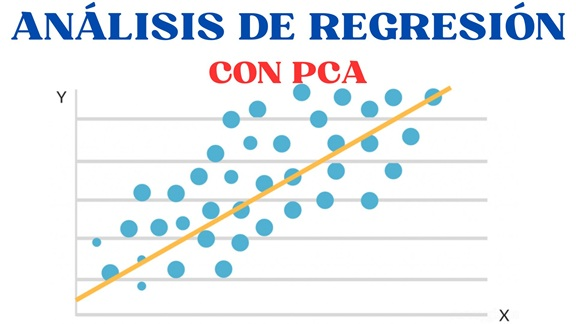


# <font color="blue"> QUE ES EL ANALISIS DE REGRESION CON PCA</font>

###El Análisis de Regresión con PCA (Análisis de Componentes Principales) combina dos técnicas:
1. **Análisis de Regresión**: Modelar la relación entre una variable dependiente (respuesta) y una o más variables independientes (predictoras).
2. **PCA**: Reducir la dimensionalidad de los datos conservando la mayor varianza posible. Esto transforma las variables originales en un conjunto menor de variables no correlacionadas, llamadas **componentes principales**.

### Conceptos Clave:
1. **Regresión Lineal**:
   La regresión busca encontrar la relación lineal entre las variables predictoras \(X\) y la variable objetivo \(y\):
   $$
   y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_p X_p + \epsilon
   $$


2. **PCA**:
   - PCA encuentra nuevas variables (componentes principales) como combinaciones lineales de las variables originales.
   - La varianza explicada por cada componente indica su relevancia.

   La transformación principal de PCA se representa como:
   $$
   Z = XW
   $$


3. **Análisis de Regresión con PCA**:
   Combina PCA y regresión para superar problemas como:
   - Multicolinealidad: Correlación entre variables predictoras que afecta la estabilidad de los coeficientes.
   - Dimensionalidad alta: Cuando el número de predictores es mayor que las observaciones.

###La idea básica es:
   - Reducir las variables predictoras originales usando PCA.
   - Realizar la regresión con las componentes principales seleccionadas


# <font color="blue"> EXPLORACIÓN DE DATOS </font>
###<font color="yellow">En esta actividad analizaremos un conjunto de datos sobre la incidencia de delitos sexuales en México, enfocado en identificar las problemáticas sociales subyacentes y los principales factores que contribuyen a este grave problema, especialmente hacia las mujeres. El objetivo es explorar las variables más relevantes que actúan como detonantes para comprender mejor esta situación y plantear posibles soluciones.</font>








In [ ]:
from sklearn.datasets import load_digits
from random import randint
import numpy as np
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import BboxImage
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from matplotlib.transforms import Bbox, TransformedBbox
import pandas as pd
%matplotlib inline


In [ ]:
# Cargar el archivo Nombres.xls con los nombres descriptivos de las variables
nombres_path = "Nombres.xls"  # Ruta del archivo en el entorno
nombres_df = pd.read_excel(nombres_path)

# Crear un diccionario de mapeo de nombres
column_mapping = dict(zip(nombres_df['COLUMNA'], nombres_df['DESCRIPCIÓN']))



# <font color="blue">Carga del archivo de indicadore.cvs</font>

In [ ]:
# Cargar el archivo CSV desde Google Drive o localmente
ruta_archivo = "indicadores.csv"  # Asegúrate de cambiar la ruta si es necesario
df = pd.read_csv(ruta_archivo)
# Diccionario para reemplazar los nombres de las columnas con sus descripciones
column_mapping = {
    "mun_clv": "Clave del municipio",
    "MUN": "Nombre del municipio",
    "TS_EXP_ALCOHOL": "Expedios de alcohol por cada 100 mil habitantes",
    "POB_TOT": "Población total",
    "SALDO_NETO_MIG": "Saldo neto migratorio",
    "TS_ID": "Infraestructura deportiva",
    "T_SEX": "Tasa de delitos sexuales",
    "T_SEC": "Tasa de secuestros",
    "T_HOMIC": "Tasa de homicidios",
    "T_PAT": "Tasa de delitos patrimoniales",
    "T_LES": "Tasa de delitos por lesiones dolosas",
    "T_ROB_COM": "Tasa de robos comunes",
    "T_ACC": "Tasa de accidentes de transporte",
    "T_HOM": "Tasa de homicidios (INEGI 2010)",
    "T_SUIC": "Tasa de suicidios",
    "MORT_CE": "Mortalidad por causas externas",
    "IM": "Índice de marginación",
    "IM_100": "Índice de marginación en porcentaje",
    "ASIST_ESC_MUJ": "Asistencia escolar de mujeres",
    "ASIST_ESC_HOM": "Asistencia escolar de hombres",
    "PORC_POB_INDIG": "Porcentaje de población indígena",
    "IND_FEM": "Índice de feminidad",
    "T_PART_ECONOM": "Tasa de participación económica",
    "IDG": "Índice de desarrollo relativo al género",
    "IMMU_REZ_EDUC": "Rezago educativo (INMUJERES)",
    "GRADO_PROM": "Grado de estudios promedio",
    "ANALF_TOT": "Analfabetismo",
    "REZ_EDUC": "Rezago educativo (INEGI)",
    "DESOC_ABERT": "Desocupación abierta",
    "T_VIU_M": "Porcentaje de viudos (mujeres)",
    "T_VIU_H": "Porcentaje de viudos (hombres)",
    "DEP_DEM": "Dependencia demográfica",
    "DER_HAB_SIN": "Porcentaje sin acceso a servicios de salud",
    "C_GINI": "Coeficiente de Gini",
    "RAZ_INC": "Razón de ingreso",
    "REZ_SOC": "Rezago social",
    "POB_EXT": "Población en pobreza extrema",
    "HAC": "Hacinamiento",
    "HAC_EXT": "Hacinamiento extremo",
    "HAC_15_29": "Hacinamiento (edades 15-29)",
    "HAC_IRR": "Hacinamiento irreparable",
    "HOG_JEF_FEM": "Hogares con jefatura femenina",
}

# Reemplazar los nombres de las columnas en el DataFrame
df.rename(columns=column_mapping, inplace=True)

# Visualizar las primeras filas del DataFrame con los nuevos nombres
df.head()


,Nombre del municipio,Tasa de delitos sexuales,Expedios de alcohol por cada 100 mil habitantes,Población total,Saldo neto migratorio,Infraestructura deportiva,Índice de marginación,Índice de marginación en porcentaje,Asistencia escolar de mujeres,Asistencia escolar de hombres,...,Coeficiente de Gini,RAZ_ING,Rezago social,POB,Población en pobreza extrema,POB_JOV,HAC_SIN,Hacinamiento irreparable,Hacinamiento,Hogares con jefatura femenina
0,Aguascalientes,12.17,97.740304,797010,0.80,113.42,-1.7684,7.690,94.1,93.7,...,0.44,0.13,-1.5585,30.53,2.26,27.098154,75.988193,0.957785,23.054022,24.03
1,Calvillo,5.54,94.207182,54136,-1.24,120.07,-0.7540,19.152,91.7,88.9,...,0.38,0.13,-1.1019,61.36,7.24,26.067681,61.986605,1.960784,36.052610,22.88
2,Jesús María,5.02,89.366402,99590,7.28,52.21,-1.2622,13.411,92.9,92.0,...,0.42,0.14,-1.2965,45.34,6.08,26.545838,62.856881,2.388360,34.754758,17.49
3,Ensenada,31.49,91.042685,466814,3.07,1.29,-1.3605,12.299,93.1,92.9,...,0.45,0.11,-1.0618,36.11,5.70,27.801651,71.222589,2.076563,26.700848,25.87
4,Mexicali,19.53,100.659034,936826,1.66,2.99,-1.7544,7.849,95.4,94.9,...,0.44,0.12,-1.5479,30.15,2.64,25.986149,71.508504,1.293183,27.198313,25.42


# <font color="blue"> HISTORIGRAMA</font>

<Figure size 1200x600 with 0 Axes>

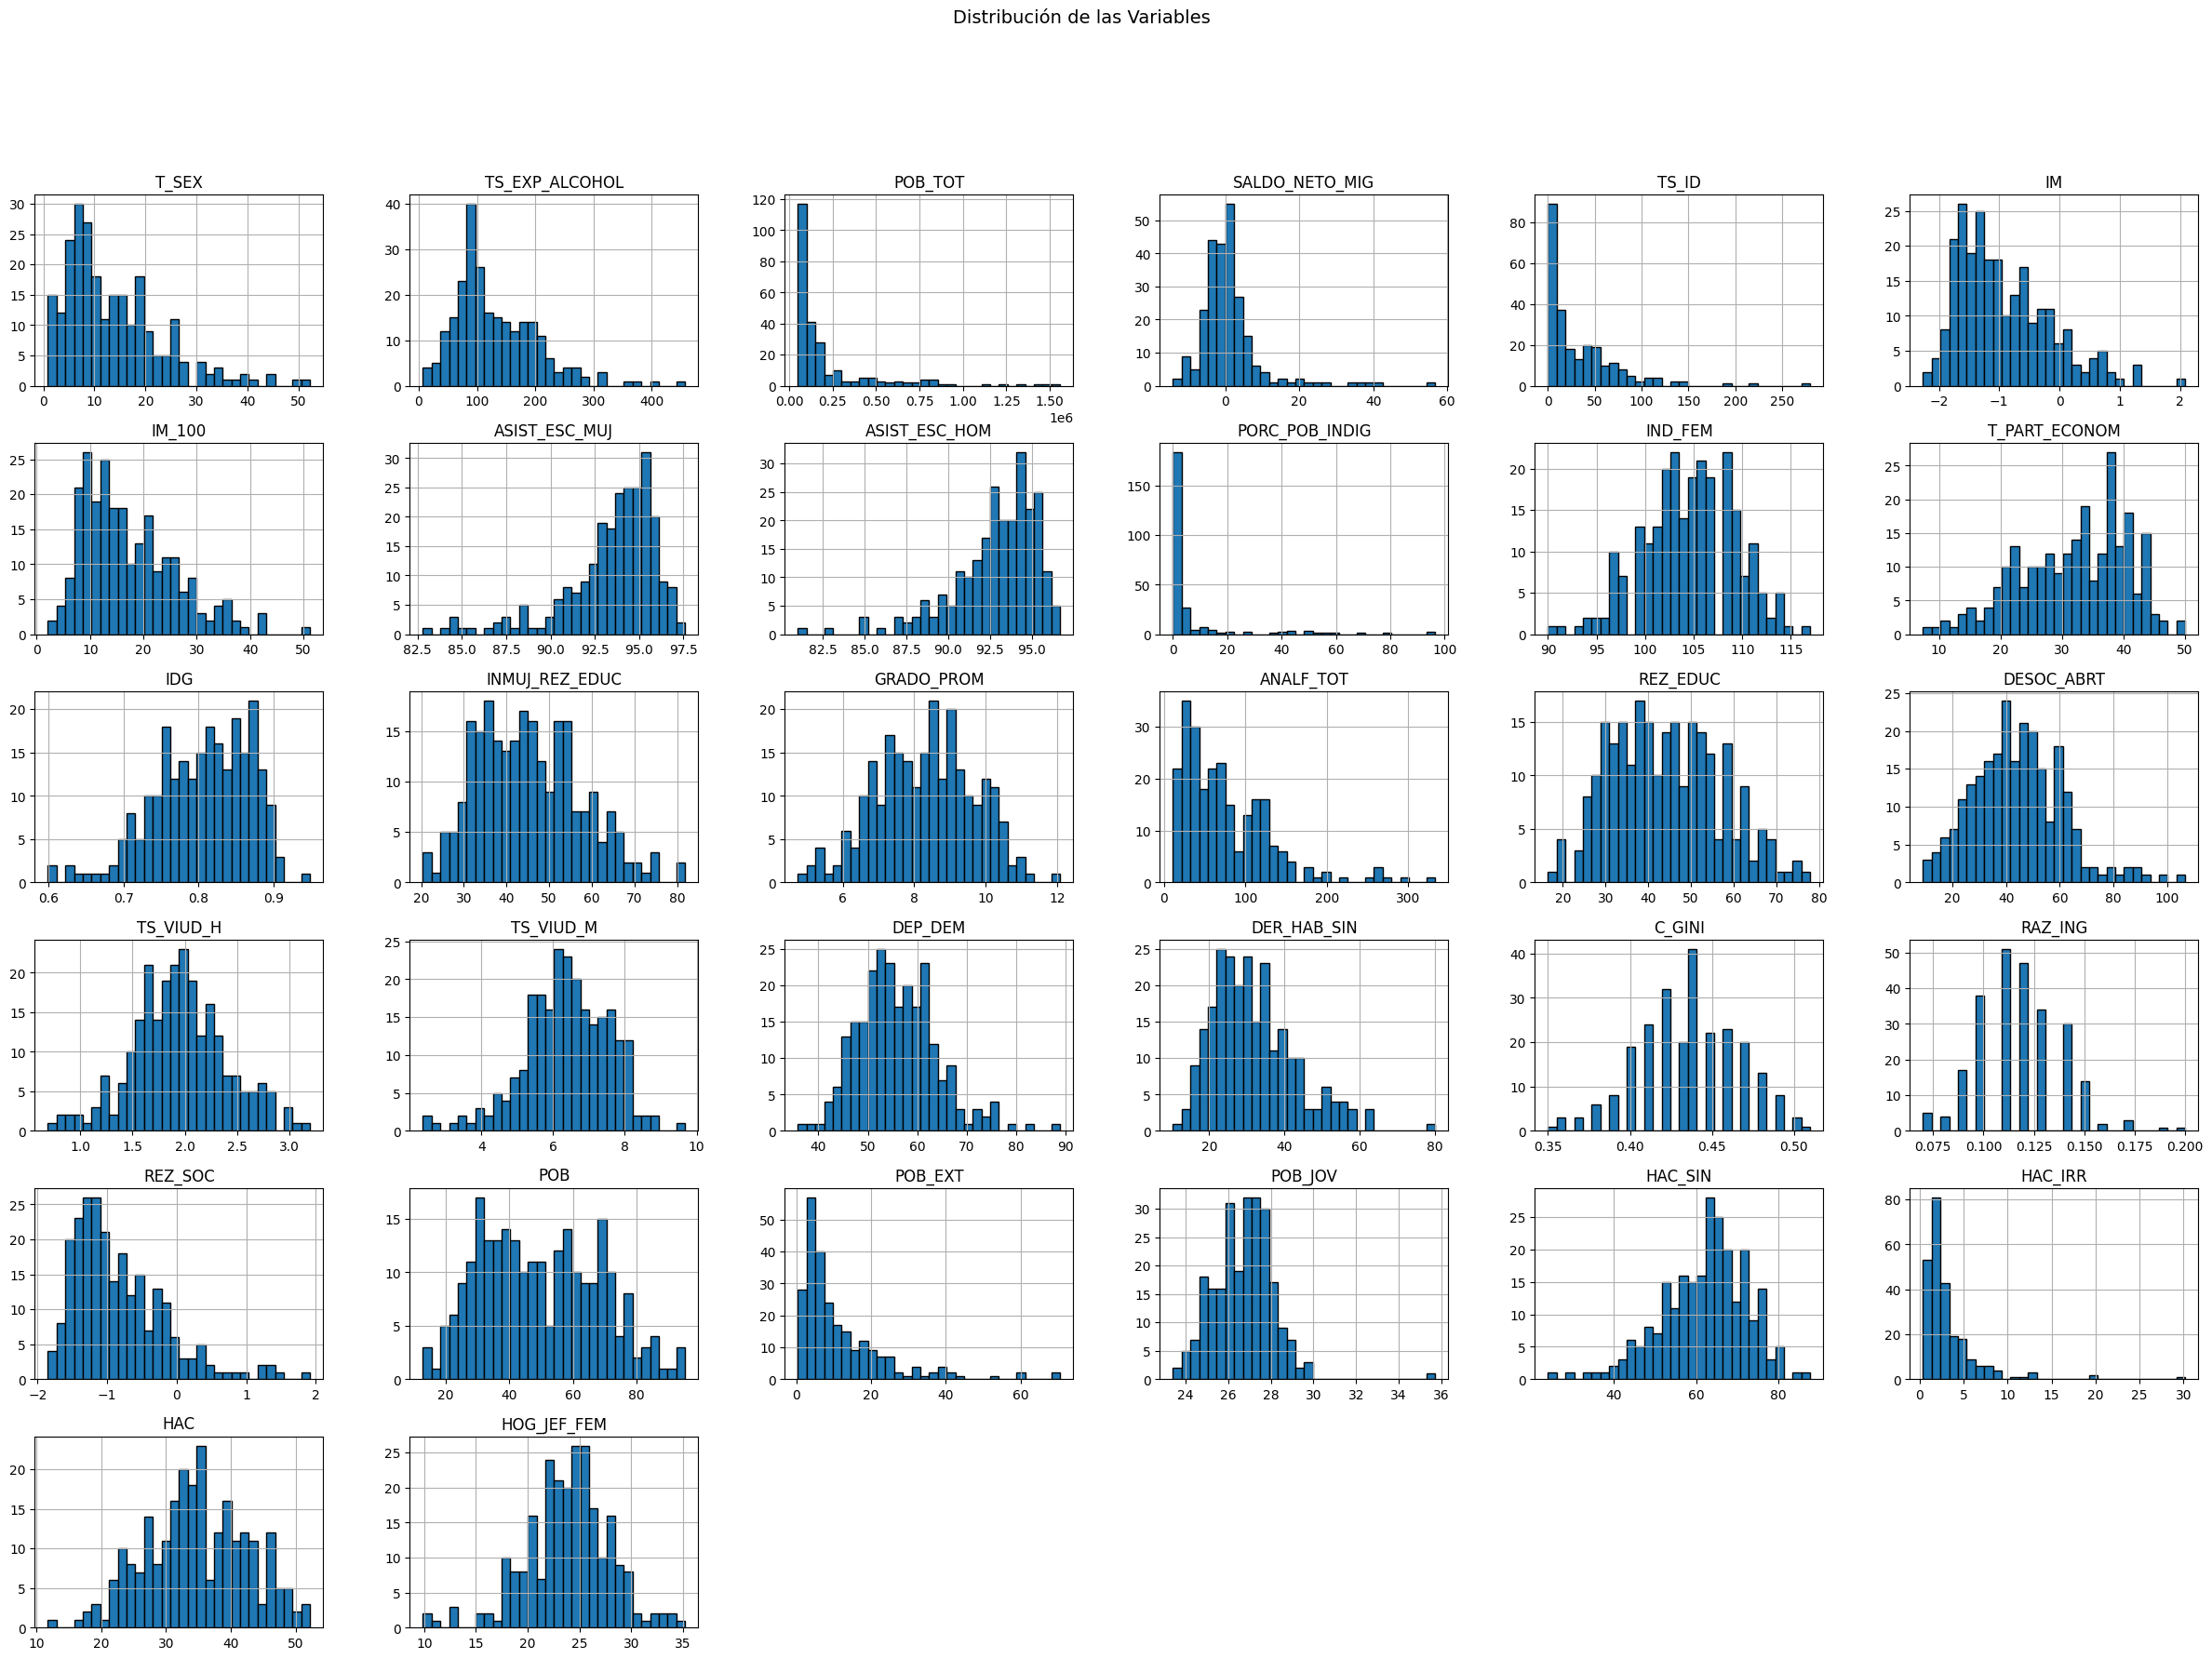

In [ ]:


# Configuración de los gráficos
plt.figure(figsize=(12, 6))
# Histograma de todas las variables numéricas
df.hist(figsize=(30, 20), bins=30, edgecolor='black')
plt.suptitle("Distribución de las Variables", fontsize=14)
plt.show()

# DATOS ATIPICOS

In [ ]:

# Función para identificar datos atípicos utilizando el método del rango intercuartílico (IQR)
def detectar_outliers_df(df):
    resultados = []
    for columna in df.select_dtypes(include=[np.number]).columns:  # Solo para columnas numéricas
        Q1 = df[columna].quantile(0.25)  # Primer cuartil
        Q3 = df[columna].quantile(0.75)  # Tercer cuartil
        IQR = Q3 - Q1  # Rango intercuartílico
        limite_inferior = Q1 - 1.5 * IQR
        limite_superior = Q3 + 1.5 * IQR
        # Contar los valores atípicos
        outliers_count = df[(df[columna] < limite_inferior) | (df[columna] > limite_superior)][columna].count()
        resultados.append({"Columna": columna, "Datos Atípicos": outliers_count})
    return pd.DataFrame(resultados)

# Detectar y mostrar los datos atípicos en un DataFrame
df_outliers = detectar_outliers_df(df)
display(df_outliers)


,Columna,Datos Atípicos
0,T_SEX,8
1,TS_EXP_ALCOHOL,6
2,POB_TOT,38
3,SALDO_NETO_MIG,16
4,TS_ID,8
5,IM,4
6,IM_100,4
7,ASIST_ESC_MUJ,14
8,ASIST_ESC_HOM,9
9,PORC_POB_INDIG,33


#CORRELACIÓN ENTRE LAS PAREJAS VARIABLES

In [ ]:
# Filtrar solo columnas numéricas para calcular la matriz de correlación
numeric_df = df.select_dtypes(include=['float64', 'int64'])

# Calcular la matriz de correlación
correlation_matrix = numeric_df.corr()

# Mostrar la matriz de correlación en un DataFrame
correlation_df = correlation_matrix.reset_index().rename(columns={'index': 'Variable'})
display(correlation_df)


,Variable,T_SEX,TS_EXP_ALCOHOL,POB_TOT,SALDO_NETO_MIG,TS_ID,IM,IM_100,ASIST_ESC_MUJ,ASIST_ESC_HOM,...,C_GINI,RAZ_ING,REZ_SOC,POB,POB_EXT,POB_JOV,HAC_SIN,HAC_IRR,HAC,HOG_JEF_FEM
0,T_SEX,1.000000,0.202765,0.179864,0.053953,-0.108136,-0.208071,-0.208070,0.097261,0.079126,...,0.071256,0.001127,-0.183720,-0.147734,-0.130260,0.174601,0.094860,-0.045566,-0.105567,0.162237
1,TS_EXP_ALCOHOL,0.202765,1.000000,-0.109540,-0.155903,0.152822,-0.109420,-0.109424,0.128786,0.118776,...,-0.021543,0.049803,-0.170559,-0.104851,-0.153510,-0.191903,0.062955,-0.104469,-0.039397,0.208954
2,POB_TOT,0.179864,-0.109540,1.000000,-0.055099,-0.189004,-0.459058,-0.459053,0.190364,0.192852,...,0.115161,-0.004370,-0.415578,-0.464514,-0.316280,0.018792,0.420220,-0.247907,-0.448624,0.184631
3,SALDO_NETO_MIG,0.053953,-0.155903,-0.055099,1.000000,0.023503,-0.255841,-0.255836,0.131482,0.111197,...,-0.170726,0.301705,-0.269778,-0.254768,-0.269595,0.091323,0.085565,-0.218923,-0.021765,-0.193215
4,TS_ID,-0.108136,0.152822,-0.189004,0.023503,1.000000,0.027744,0.027738,0.162365,0.166126,...,-0.150939,0.134511,-0.071413,0.045114,-0.089751,0.065557,-0.093835,-0.049538,0.143510,-0.110068
5,IM,-0.208071,-0.109420,-0.459058,-0.255841,0.027744,1.000000,1.000000,-0.576250,-0.463835,...,0.210171,-0.324836,0.966423,0.924197,0.915529,0.124601,-0.865928,0.798627,0.805578,-0.454644
6,IM_100,-0.208070,-0.109424,-0.459053,-0.255836,0.027738,1.000000,1.000000,-0.576249,-0.463833,...,0.210175,-0.324837,0.966423,0.924196,0.915529,0.124602,-0.865928,0.798627,0.805579,-0.454645
7,ASIST_ESC_MUJ,0.097261,0.128786,0.190364,0.131482,0.162365,-0.576250,-0.576249,1.000000,0.937870,...,-0.098467,0.162005,-0.644682,-0.568827,-0.600397,-0.267023,0.496625,-0.536182,-0.429728,0.343475
8,ASIST_ESC_HOM,0.079126,0.118776,0.192852,0.111197,0.166126,-0.463835,-0.463833,0.937870,1.000000,...,-0.020350,0.101727,-0.541929,-0.487906,-0.463544,-0.215137,0.388738,-0.377440,-0.353831,0.196611
9,PORC_POB_INDIG,0.002658,-0.086852,-0.132466,-0.184792,0.058403,0.564365,0.564366,-0.246550,-0.087690,...,0.384828,-0.418975,0.602143,0.447583,0.668248,0.157683,-0.551629,0.757643,0.410370,-0.452578


# <font color="RED"> MAPA DE CALOR DE LA CORRELACIÓNENTRE VARIABLES </font>

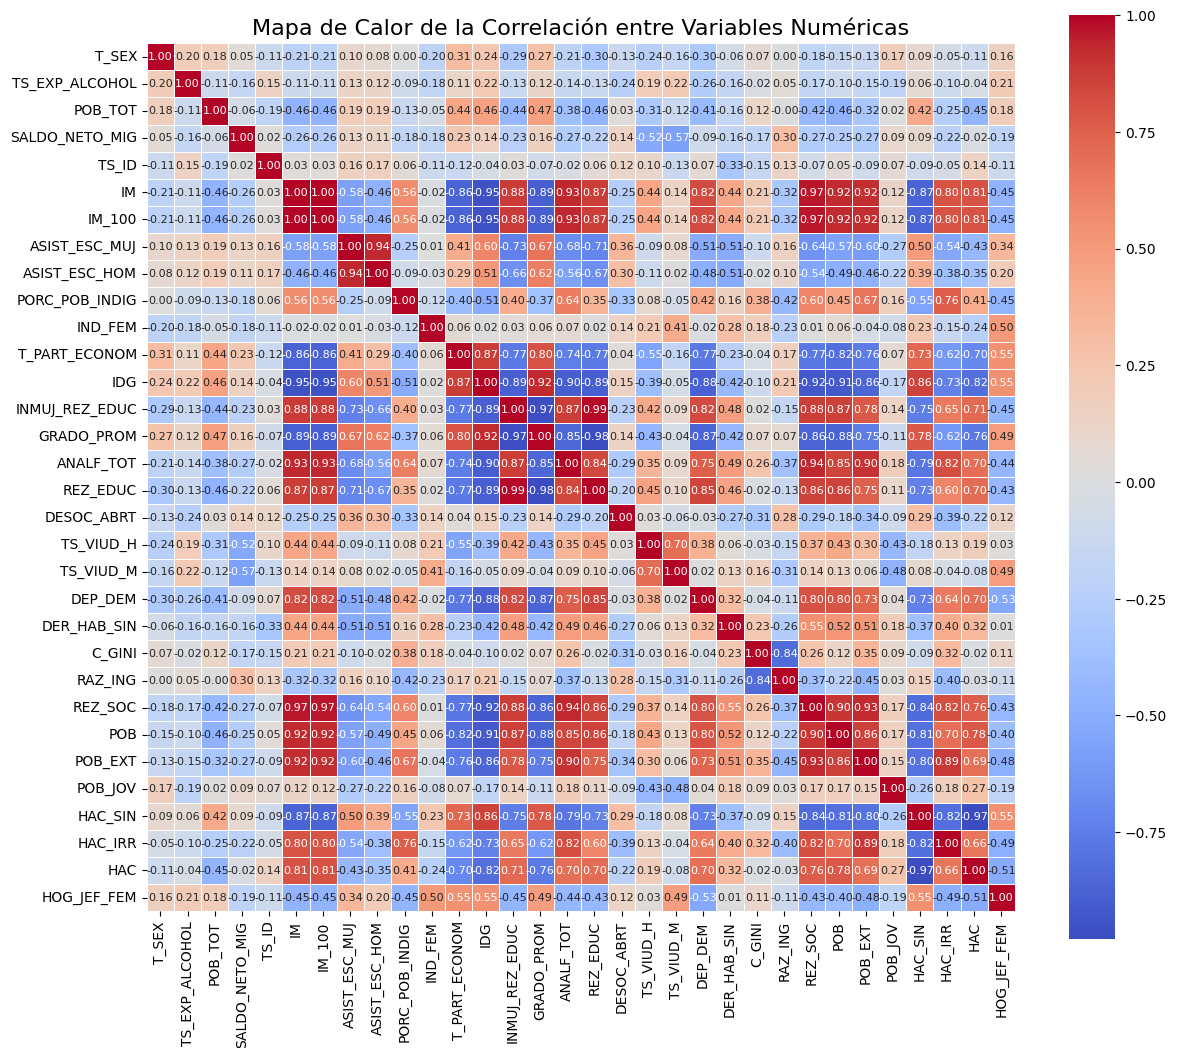

In [ ]:
# Filtrar solo columnas numéricas para calcular la matriz de correlación
numeric_df = df.select_dtypes(include=['float64', 'int64'])

# Calcular la matriz de correlación
correlation_matrix = numeric_df.corr()

# Graficar la matriz de correlación como un mapa de calor
plt.figure(figsize=(14, 12))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True,
            linewidths=0.5, annot_kws={"size": 8})
plt.title("Mapa de Calor de la Correlación entre Variables Numéricas", fontsize=16)
plt.show()


#IDENTIFICACION DE VARIABLES DUPLICADAS

In [ ]:
# Visualizar el porcentaje de valores faltantes por columna
missing_values = df.isnull().sum() / len(df) * 100
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

# Mostrar solo las variables con datos faltantes
if not missing_values.empty:
    print("\n📌 Variables con valores faltantes (% de datos faltantes):")
    print(missing_values)
else:
    print("\n✅ No hay valores faltantes en el dataset.")

# Identificar columnas duplicadas
duplicates = df.T.duplicated()
if duplicates.any():
    print("\n📌 Se encontraron variables duplicadas, procederemos a eliminarlas.")
    df = df.loc[:, ~df.T.duplicated()]
    print(f"✅ Se eliminaron variables duplicadas. Ahora el dataset tiene {df.shape[1]} variables.")
else:
    print("\n✅ No se encontraron variables duplicadas.")



✅ No hay valores faltantes en el dataset.

✅ No se encontraron variables duplicadas.


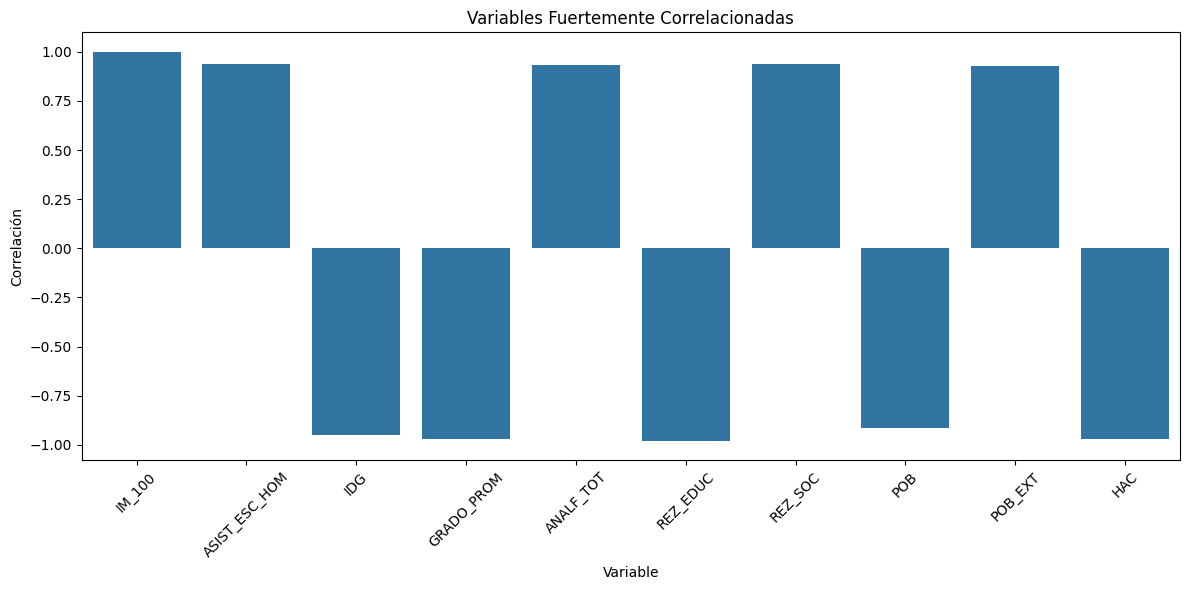

In [ ]:
# Select only numerical columns for correlation calculation
numerical_df = df.select_dtypes(include=np.number)

# Calculate the correlation matrix on the numerical DataFrame
correlation_matrix = numerical_df.corr()

# Umbral para considerar que dos variables están altamente correlacionadas (ejemplo: > 0.9)
umbral_correlacion = 0.9

# Encontrar las variables redundantes y sus correlaciones
correlated_vars = {}  # Store as a dictionary {variable: correlation}
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > umbral_correlacion:
            colname = correlation_matrix.columns[i]
            correlated_vars[colname] = correlation_matrix.iloc[i, j]  # Store correlation value

# Create a DataFrame for plotting
correlated_vars_df = pd.DataFrame(list(correlated_vars.items()), columns=['Variable', 'Correlación'])

# Plot the bar chart using Seaborn
plt.figure(figsize=(12, 6))  # Adjust figure size as needed
sns.barplot(x='Variable', y='Correlación', data=correlated_vars_df)
plt.title('Variables Fuertemente Correlacionadas')
plt.xticks(rotation=45)  # Rotate x-axis labels for readability
plt.tight_layout()
plt.show()

# <font color="blue"> SELECCIÓN DE NUMEROS DE COMPONENTES PRINCIPALES</font>

#ANALISIS DE COMPONENTES PRINCIPALES


In [ ]:
dat = pd.read_csv("indicadores.csv")
dat.head()

,MUN,T_SEX,TS_EXP_ALCOHOL,POB_TOT,SALDO_NETO_MIG,TS_ID,IM,IM_100,ASIST_ESC_MUJ,ASIST_ESC_HOM,...,C_GINI,RAZ_ING,REZ_SOC,POB,POB_EXT,POB_JOV,HAC_SIN,HAC_IRR,HAC,HOG_JEF_FEM
0,Aguascalientes,12.17,97.740304,797010,0.80,113.42,-1.7684,7.690,94.1,93.7,...,0.44,0.13,-1.5585,30.53,2.26,27.098154,75.988193,0.957785,23.054022,24.03
1,Calvillo,5.54,94.207182,54136,-1.24,120.07,-0.7540,19.152,91.7,88.9,...,0.38,0.13,-1.1019,61.36,7.24,26.067681,61.986605,1.960784,36.052610,22.88
2,Jesús María,5.02,89.366402,99590,7.28,52.21,-1.2622,13.411,92.9,92.0,...,0.42,0.14,-1.2965,45.34,6.08,26.545838,62.856881,2.388360,34.754758,17.49
3,Ensenada,31.49,91.042685,466814,3.07,1.29,-1.3605,12.299,93.1,92.9,...,0.45,0.11,-1.0618,36.11,5.70,27.801651,71.222589,2.076563,26.700848,25.87
4,Mexicali,19.53,100.659034,936826,1.66,2.99,-1.7544,7.849,95.4,94.9,...,0.44,0.12,-1.5479,30.15,2.64,25.986149,71.508504,1.293183,27.198313,25.42


# <font color="GREEN"> MATRIZ DE CONVARIANZA</font>

In [ ]:
# Convertir el DataFrame a una matriz de valores
X = df.select_dtypes(include=['float64', 'int64']).values  # Matriz de datos

# Calcular la media de cada variable
xm = np.mean(X, axis=0)

# Calcular la matriz de covarianza
C = np.dot(np.transpose(X - xm), (X - xm)) / (len(X) - 1)

# Convertir la matriz de covarianza en un DataFrame
df_covarianza = pd.DataFrame(C, index=df.select_dtypes(include=['float64', 'int64']).columns,
                             columns=df.select_dtypes(include=['float64', 'int64']).columns)

# Mostrar la matriz de covarianza en DataFrame
display(df_covarianza)


,T_SEX,TS_EXP_ALCOHOL,POB_TOT,SALDO_NETO_MIG,TS_ID,IM,IM_100,ASIST_ESC_MUJ,ASIST_ESC_HOM,PORC_POB_INDIG,...,C_GINI,RAZ_ING,REZ_SOC,POB,POB_EXT,POB_JOV,HAC_SIN,HAC_IRR,HAC,HOG_JEF_FEM
T_SEX,91.983011,1.393774e+02,4.582040e+05,4.310251,-4.084911e+01,-1.540538,-1.740743e+01,2.490154,1.913358,0.377276,...,0.020931,0.000222,-1.175070,-2.633216e+01,-14.767613,2.360212,9.345788e+00,-1.414230,-7.931559,6.352725
TS_EXP_ALCOHOL,139.377407,5.136775e+03,-2.085345e+06,-93.075366,4.314102e+02,-6.054102,-6.841176e+01,24.640457,21.463344,-92.120506,...,-0.047289,0.073279,-8.152166,-1.396597e+02,-130.055340,-19.385598,4.635047e+01,-24.230324,-22.120149,61.143652
POB_TOT,458203.989675,-2.085345e+06,7.055432e+10,-121910.846894,-1.977391e+06,-94131.798466,-1.063645e+06,134983.552082,129154.197882,-520709.963745,...,936.870740,-23.829293,-73615.331368,-2.293045e+06,-993066.068934,7035.231030,1.146610e+06,-213096.828316,-933513.548660,200226.582730
SALDO_NETO_MIG,4.310251,-9.307537e+01,-1.219108e+05,69.385849,7.711211e+00,-1.645177,-1.858953e+01,2.923710,2.335349,-22.779830,...,-0.043556,0.051594,-1.498639,-3.943957e+01,-26.545594,1.072178,7.321651e+00,-5.901389,-1.420262,-6.570993
TS_ID,-40.849108,4.314102e+02,-1.977391e+06,7.711211,1.551379e+03,0.843608,9.530437e+00,17.072051,16.497539,34.042827,...,-0.182083,0.108767,-1.875829,3.302359e+01,-41.786996,3.639420,-3.796655e+01,-6.314323,44.280872,-17.700159
IM,-1.540538,-6.054102e+00,-9.413180e+04,-1.645177,8.436077e-01,0.595957,6.734095e+00,-1.187550,-0.902803,6.447609,...,0.004969,-0.005148,0.497541,1.325940e+01,8.354578,0.135575,-6.866986e+00,1.995163,4.871823,-1.432961
IM_100,-17.407429,-6.841176e+01,-1.063645e+06,-18.589535,9.530437e+00,6.734095,7.609283e+01,-13.418851,-10.201314,72.855758,...,0.056152,-0.058172,5.622032,1.498261e+02,94.403656,1.531961,-7.759452e+01,22.544619,55.049903,-16.191955
ASIST_ESC_MUJ,2.490154,2.464046e+01,1.349836e+05,2.923710,1.707205e+01,-1.187550,-1.341885e+01,7.126351,6.312458,-9.740241,...,-0.008051,0.008879,-1.147714,-2.822056e+01,-18.945970,-1.004695,1.361882e+01,-4.632047,-8.986773,3.743552
ASIST_ESC_HOM,1.913358,2.146334e+01,1.291542e+05,2.335349,1.649754e+01,-0.902803,-1.020131e+01,6.312458,6.356893,-3.271930,...,-0.001571,0.005266,-0.911211,-2.286177e+01,-13.815245,-0.764521,1.006830e+01,-3.079621,-6.988682,2.023884
PORC_POB_INDIG,0.377276,-9.212051e+01,-5.207100e+05,-22.779830,3.404283e+01,6.447609,7.285576e+01,-9.740241,-3.271930,219.009002,...,0.174425,-0.127292,5.942714,1.230996e+02,116.899824,3.289017,-8.386009e+01,36.284594,47.575496,-27.345142


# <font color="GREEN"> DIMENCIONES DE LA MATRIZ DE COVARIANZA</font>

In [ ]:
# Cargar el archivo CSV y seleccionar solo las columnas numéricas
numeric_df = df.select_dtypes(include=['float64', 'int64'])

# Convertir el DataFrame a una matriz de valores
X = numeric_df.values  # Matriz de datos

# Calcular la media de cada variable
xm = np.mean(X, axis=0)

# Calcular la matriz de covarianza
C = np.dot(np.transpose(X - xm), (X - xm)) / (len(X) - 1)

# Mostrar dimensiones y la matriz de covarianza resultante
print(f"Dimensiones de la matriz de covarianza: {C.shape}")
print("Matriz de covarianza:")
display(pd.DataFrame(C, index=numeric_df.columns, columns=numeric_df.columns))

Dimensiones de la matriz de covarianza: (32, 32)
Matriz de covarianza:


,T_SEX,TS_EXP_ALCOHOL,POB_TOT,SALDO_NETO_MIG,TS_ID,IM,IM_100,ASIST_ESC_MUJ,ASIST_ESC_HOM,PORC_POB_INDIG,...,C_GINI,RAZ_ING,REZ_SOC,POB,POB_EXT,POB_JOV,HAC_SIN,HAC_IRR,HAC,HOG_JEF_FEM
T_SEX,91.983011,1.393774e+02,4.582040e+05,4.310251,-4.084911e+01,-1.540538,-1.740743e+01,2.490154,1.913358,0.377276,...,0.020931,0.000222,-1.175070,-2.633216e+01,-14.767613,2.360212,9.345788e+00,-1.414230,-7.931559,6.352725
TS_EXP_ALCOHOL,139.377407,5.136775e+03,-2.085345e+06,-93.075366,4.314102e+02,-6.054102,-6.841176e+01,24.640457,21.463344,-92.120506,...,-0.047289,0.073279,-8.152166,-1.396597e+02,-130.055340,-19.385598,4.635047e+01,-24.230324,-22.120149,61.143652
POB_TOT,458203.989675,-2.085345e+06,7.055432e+10,-121910.846894,-1.977391e+06,-94131.798466,-1.063645e+06,134983.552082,129154.197882,-520709.963745,...,936.870740,-23.829293,-73615.331368,-2.293045e+06,-993066.068934,7035.231030,1.146610e+06,-213096.828316,-933513.548660,200226.582730
SALDO_NETO_MIG,4.310251,-9.307537e+01,-1.219108e+05,69.385849,7.711211e+00,-1.645177,-1.858953e+01,2.923710,2.335349,-22.779830,...,-0.043556,0.051594,-1.498639,-3.943957e+01,-26.545594,1.072178,7.321651e+00,-5.901389,-1.420262,-6.570993
TS_ID,-40.849108,4.314102e+02,-1.977391e+06,7.711211,1.551379e+03,0.843608,9.530437e+00,17.072051,16.497539,34.042827,...,-0.182083,0.108767,-1.875829,3.302359e+01,-41.786996,3.639420,-3.796655e+01,-6.314323,44.280872,-17.700159
IM,-1.540538,-6.054102e+00,-9.413180e+04,-1.645177,8.436077e-01,0.595957,6.734095e+00,-1.187550,-0.902803,6.447609,...,0.004969,-0.005148,0.497541,1.325940e+01,8.354578,0.135575,-6.866986e+00,1.995163,4.871823,-1.432961
IM_100,-17.407429,-6.841176e+01,-1.063645e+06,-18.589535,9.530437e+00,6.734095,7.609283e+01,-13.418851,-10.201314,72.855758,...,0.056152,-0.058172,5.622032,1.498261e+02,94.403656,1.531961,-7.759452e+01,22.544619,55.049903,-16.191955
ASIST_ESC_MUJ,2.490154,2.464046e+01,1.349836e+05,2.923710,1.707205e+01,-1.187550,-1.341885e+01,7.126351,6.312458,-9.740241,...,-0.008051,0.008879,-1.147714,-2.822056e+01,-18.945970,-1.004695,1.361882e+01,-4.632047,-8.986773,3.743552
ASIST_ESC_HOM,1.913358,2.146334e+01,1.291542e+05,2.335349,1.649754e+01,-0.902803,-1.020131e+01,6.312458,6.356893,-3.271930,...,-0.001571,0.005266,-0.911211,-2.286177e+01,-13.815245,-0.764521,1.006830e+01,-3.079621,-6.988682,2.023884
PORC_POB_INDIG,0.377276,-9.212051e+01,-5.207100e+05,-22.779830,3.404283e+01,6.447609,7.285576e+01,-9.740241,-3.271930,219.009002,...,0.174425,-0.127292,5.942714,1.230996e+02,116.899824,3.289017,-8.386009e+01,36.284594,47.575496,-27.345142


### Valores y vectores propios

In [ ]:
l, v = np.linalg.eig(C)
print(l)
print("#####")
print(v)

[ 7.05543181e+10  5.48071984e+03  3.11920469e+03  1.47506372e+03
  2.50276167e+02  1.67769765e+02  1.18216835e+02  8.91329376e+01
  7.34287539e+01  5.97937393e+01  4.07534708e+01  3.03550389e+01
  1.98247144e+01  1.28448958e+01  1.14141623e+01  8.31399816e+00
  5.54900943e+00  3.33654174e+00  1.85783915e+00  1.51179592e+00
  1.00234491e+00  6.01350376e-01  3.21671003e-01  1.43414624e-01
  3.81025454e-02  2.48409650e-02  9.22011376e-03  5.14968325e-04
  1.17151892e-04  6.60998434e-05  1.01623806e-09 -3.20867960e-14]
#####
[[ 6.49434378e-06  3.13842314e-02  4.14410607e-03 ...  6.82334088e-05
  -9.59653242e-09 -3.01968608e-11]
 [-2.95565957e-05  9.18496522e-01 -3.76034226e-01 ... -4.40326292e-06
  -5.83145751e-08 -4.92134848e-12]
 [ 9.99999994e-01 -6.27107254e-06 -9.74873727e-05 ... -4.93619577e-09
   1.05101661e-11 -2.85202224e-16]
 ...
 [-3.02032318e-06 -1.55608400e-02 -4.15106566e-02 ...  4.12973971e-04
  -2.57120917e-05 -5.77350269e-01]
 [-1.32311332e-05 -2.69453326e-02 -7.62252836e-0

### Total de componentes principales

En esta celda decidimos el total de componentes principales que debemos seleccionar para proyectar nuestros datos, esto es, decidimos la dimensión del nuevo espacio:

In [ ]:
var_tot = sum(l)
np.cumsum(l)/var_tot*100 #total de varianza acumulada

array([ 99.99998445,  99.99999222,  99.99999664,  99.99999873,
        99.99999908,  99.99999932,  99.99999949,  99.99999962,
        99.99999972,  99.9999998 ,  99.99999986,  99.99999991,
        99.99999993,  99.99999995,  99.99999997,  99.99999998,
        99.99999999,  99.99999999,  99.99999999, 100.        ,
       100.        , 100.        , 100.        , 100.        ,
       100.        , 100.        , 100.        , 100.        ,
       100.        , 100.        , 100.        , 100.        ])

Observa que es suficiente con utilizar las dos componentes principales para que la proyección preserve casi el 90% de la información del conjunto de datos original.

### Matriz de proyección

La matriz de proyección estará compuesta por dos columnas, cada una de las cuales corresponde a un vector principal:

In [ ]:
A = v[:,:2] #seleccionamos los dos primeros vectores principales
A #matriz de 4 x 2

array([[ 6.49434378e-06,  3.13842314e-02],
       [-2.95565957e-05,  9.18496522e-01],
       [ 9.99999994e-01, -6.27107254e-06],
       [-1.72790034e-06, -5.86292036e-03],
       [-2.80265124e-05,  1.06624089e-01],
       [-1.33417493e-06, -4.11267539e-03],
       [-1.50755493e-05, -4.64721898e-02],
       [ 1.91318639e-06,  1.22331510e-02],
       [ 1.83056414e-06,  9.92662785e-03],
       [-7.38027139e-06, -5.48166085e-02],
       [-8.04089875e-07, -1.15853627e-02],
       [ 1.43671270e-05,  3.93605148e-02],
       [ 1.10487187e-07,  4.09777051e-04],
       [-2.00068625e-05, -6.50245170e-02],
       [ 2.45457534e-06,  7.08256007e-03],
       [-7.89314038e-05, -3.25875903e-01],
       [-2.14768205e-05, -6.43958340e-02],
       [ 2.16955751e-06, -2.66343435e-02],
       [-5.12314199e-07,  3.81940756e-04],
       [-5.56018403e-07,  2.58064428e-03],
       [-1.25412259e-05, -5.20214343e-02],
       [-6.61263018e-06, -4.85764315e-02],
       [ 1.32787152e-08, -4.39862649e-05],
       [-3.

# <font color="YELLOW"> PROYECCIÓN</font>

La proyección la realizamos multiplicando la matriz de datos por la de proyección:

In [ ]:
Xp = np.dot(X, A)
Xp.shape

(247, 2)

In [ ]:
#los datos originales tienen una dimensionalidad de 4
X.shape

(247, 32)

In [ ]:
# revisamos la proyección de las primeras observaciones
Xp[:10,:]

array([[7.97009986e+05, 8.12223351e+01],
       [5.41359845e+04, 6.16928359e+01],
       [9.95899894e+04, 6.25364409e+01],
       [4.66813989e+05, 5.70732123e+01],
       [9.36825989e+05, 7.30304369e+01],
       [1.01078994e+05, 5.48343151e+01],
       [1.55968299e+06, 3.77722078e+01],
       [9.06679923e+04, 7.09216046e+01],
       [7.08159814e+04, 2.69931930e+02],
       [5.91139836e+04, 1.59116371e+02]])

In [ ]:
X[0,]

array([ 1.21700000e+01,  9.77403044e+01,  7.97010000e+05,  8.00000000e-01,
        1.13420000e+02, -1.76840000e+00,  7.69000000e+00,  9.41000000e+01,
        9.37000000e+01,  2.00000000e-01,  1.06000000e+02,  4.04000000e+01,
        8.68400000e-01,  3.30000000e+01,  9.81000000e+00,  2.59100000e+01,
        3.09300000e+01,  6.23787000e+01,  1.68000000e+00,  5.72000000e+00,
        5.37100000e+01,  2.23900000e+01,  4.40000000e-01,  1.30000000e-01,
       -1.55850000e+00,  3.05300000e+01,  2.26000000e+00,  2.70981544e+01,
        7.59881931e+01,  9.57785185e-01,  2.30540217e+01,  2.40300000e+01])

# CON SKLEARN
## Varianza explicada por cada componente

In [ ]:
pca = PCA(n_components=4) # usamos todas las dimensiones inicialmente para identificar el total de varianza proyectada
pca_examen = pca.fit(X)
np.cumsum(pca_examen.explained_variance_ratio_*100)

array([99.99998445, 99.99999222, 99.99999664, 99.99999873])

## EN PORCENTAJES

In [ ]:
np.cumsum(pca_examen.explained_variance_ratio_*100)

array([99.99998445, 99.99999222, 99.99999664, 99.99999873])

## PROYECTAMOS A 2 COMPONENENTES

In [ ]:
pca = PCA(n_components=2) # usamos todas las dimensiones inicialmente para identificar el total de varianza proyectada
pca.fit(X)
pca.transform(X)

array([[ 5.82840726e+05, -3.49436877e+00],
       [-1.60033275e+05, -2.30238681e+01],
       [-1.14579271e+05, -2.21802630e+01],
       [ 2.52644729e+05, -2.76434917e+01],
       [ 7.22656729e+05, -1.16862670e+01],
       [-1.13090266e+05, -2.98823888e+01],
       [ 1.34551373e+06, -4.69444961e+01],
       [-1.23501268e+05, -1.37950993e+01],
       [-1.43353279e+05,  1.85215226e+02],
       [-1.55055276e+05,  7.43996669e+01],
       [ 3.77017297e+04,  7.75755599e+01],
       [ 2.43177284e+04,  6.24893784e+01],
       [-1.61279286e+05,  6.37943312e+01],
       [ 4.48357254e+04,  6.58912093e+01],
       [ 6.92472338e+03,  8.80316046e+01],
       [-1.31148285e+05,  1.52965729e+01],
       [-1.59985283e+05, -1.08784130e+01],
       [ 5.10953729e+05,  1.50924641e+01],
       [-6.72652713e+04,  6.00398954e+01],
       [-5.27492710e+04,  1.70664842e+01],
       [-1.01443277e+05, -2.75272771e+01],
       [-9.42132663e+04, -1.17368236e+01],
       [-1.36055283e+05,  2.06383281e+01],
       [-7.

# <font color="RED"> Análisis de componentes principales
</font>

La idea del **análisis de componentes principales** es la de construir nuevas variables (nuevos ejes coordenados) a partir de una transformación lineal de las originales.

* Una **transformación lineal** genera nuevos ejes para ubicar a los datos originales.

Vamos a imponer algunas condiciones a la transformación lineal.

# <font color="yellow"> Tranformación de linea arbitraria
</font>

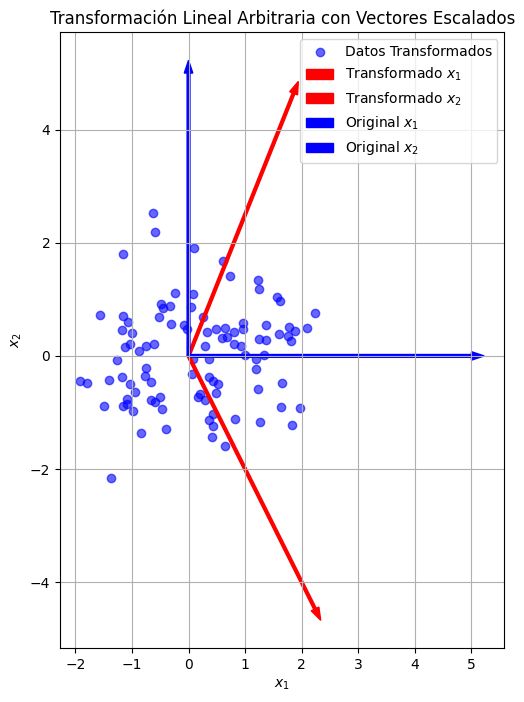

In [ ]:
# Simular datos para Xt si no está definido
Xt = np.random.randn(100, 2)  # Datos de ejemplo para visualización

# Variables originales (vectores base)
x1 = np.array([1, 0])
x2 = np.array([0, 1])

# Variables transformadas (ejemplos arbitrarios)
x1t = x1 - 2 * x2
x1t = x1t / np.linalg.norm(x1t)

x2t = 2 * x1 + 5 * x2
x2t = x2t / np.linalg.norm(x2t)

# Ajuste del tamaño de la figura
fig, ax = plt.subplots(figsize=(8, 8))  # Se amplió el tamaño para mejor visualización

# Graficar los datos transformados
plt.scatter(Xt[:, 0], Xt[:, 1], color='b', alpha=0.6, label="Datos Transformados")

# Ajustar la escala de los vectores para mayor visibilidad
escalar = 5

# Graficar vectores transformados
plt.arrow(0, 0, escalar * x1t[0], escalar * x1t[1], width=0.05, color="r", label="Transformado $x_1$")
plt.arrow(0, 0, escalar * x2t[0], escalar * x2t[1], width=0.05, color="r", label="Transformado $x_2$")

# Graficar vectores originales
plt.arrow(0, 0, escalar * x1[0], escalar * x1[1], width=0.05, color="b", label="Original $x_1$")
plt.arrow(0, 0, escalar * x2[0], escalar * x2[1], width=0.05, color="b", label="Original $x_2$")

# Configuración del gráfico
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Transformación Lineal Arbitraria con Vectores Escalados")
ax.set_aspect('equal')
plt.legend()
plt.grid(True)

# Mostrar la gráfica
plt.show()


# <font color="yellow"> Transformacion ejes ortogonales
</font>

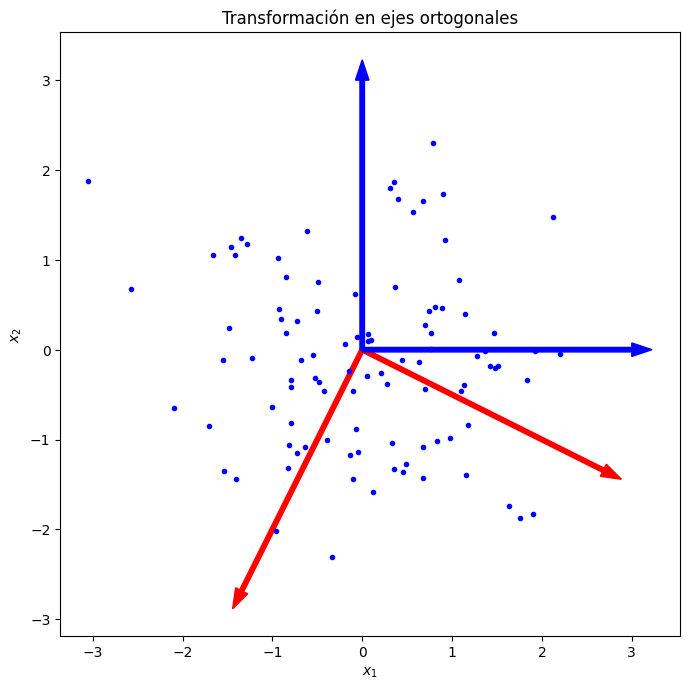

In [ ]:
#variables originales
x1 = np.array([1,0])
x2 = np.array([0,1])

#variables transformadas (ejemplos arbitrarios)
x1t = np.array([2,-1])
x1t = x1t/np.linalg.norm(x1t)

x2t = np.array([x1t[1],-x1t[0]])
x2t = x2t/np.linalg.norm(x2t)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111)


plt.plot(Xt[:,0],Xt[:,1],'b.')
plt.arrow(0,0,3*x1t[0],3*x1t[1], width=0.05, color="r")
plt.arrow(0,0,3*x2t[0],3*x2t[1], width=0.05, color="r")
plt.arrow(0,0,3*x1[0],3*x1[1], width=0.05, color="b")
plt.arrow(0,0,3*x2[0],3*x2[1], width=0.05, color="b")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Transformación en ejes ortogonales")

ax.set_aspect('equal')

plt.show()

# <font color="yellow"> Dirección de maxima varianza
</font>

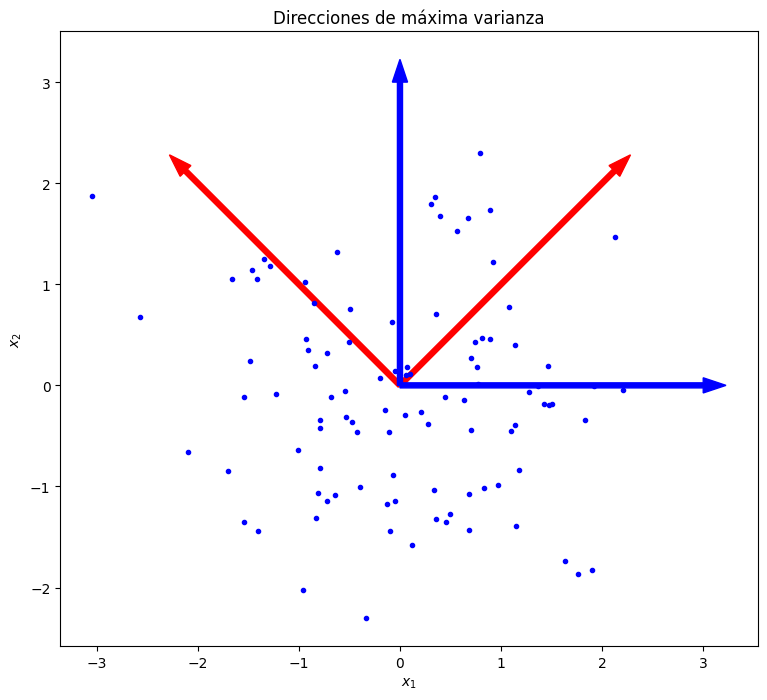

In [ ]:
#variables originales
x1 = np.array([1,0])
x2 = np.array([0,1])

#variables transformadas (ejemplos arbitrarios)
x1t = np.array([1,1])
x1t = x1t/np.linalg.norm(x1t)

x2t = np.array([-x1t[1],x1t[0]])
x2t = x2t/np.linalg.norm(x2t)

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111)
plt.plot(Xt[:,0],Xt[:,1],'b.')
plt.arrow(0,0,3*x1t[0],3*x1t[1], width=0.05, color="r")
plt.arrow(0,0,3*x2t[0],3*x2t[1], width=0.05, color="r")
plt.arrow(0,0,3*x1[0],3*x1[1], width=0.05, color="b")
plt.arrow(0,0,3*x2[0],3*x2[1], width=0.05, color="b")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Direcciones de máxima varianza")
ax.set_aspect('equal')
plt.show()

In [ ]:
X

array([[1.21700000e+01, 9.77403044e+01, 7.97010000e+05, ...,
        9.57785185e-01, 2.30540217e+01, 2.40300000e+01],
       [5.54000000e+00, 9.42071819e+01, 5.41360000e+04, ...,
        1.96078431e+00, 3.60526103e+01, 2.28800000e+01],
       [5.02000000e+00, 8.93664022e+01, 9.95900000e+04, ...,
        2.38836018e+00, 3.47547584e+01, 1.74900000e+01],
       ...,
       [1.27600000e+01, 1.89813855e+02, 6.26930000e+04, ...,
        1.22118461e+00, 3.09083785e+01, 2.34300000e+01],
       [8.17000000e+00, 1.37281820e+02, 6.11880000e+04, ...,
        1.25179293e+00, 3.22727865e+01, 1.81300000e+01],
       [2.31600000e+01, 1.55598657e+02, 1.38176000e+05, ...,
        6.78288980e-01, 1.91104312e+01, 2.71400000e+01]])

##Vector con las medias de las dos variables:

In [ ]:
xm = np.mean(X, axis = 0)
xm

array([ 1.36800000e+01,  1.31374665e+02,  2.14169275e+05,  8.63765182e-01,
        3.36947368e+01, -9.18678138e-01,  1.72918097e+01,  9.34380567e+01,
        9.28473684e+01,  5.98502024e+00,  1.04477733e+02,  3.18979757e+01,
        8.04735628e-01,  4.53817814e+01,  8.30554656e+00,  7.61778947e+01,
        4.40434008e+01,  4.41864368e+01,  1.95085020e+00,  6.37995951e+00,
        5.59965992e+01,  3.17505668e+01,  4.35263158e-01,  1.18178138e-01,
       -8.24351417e-01,  4.95995142e+01,  1.18280567e+01,  2.67211131e+01,
        6.20628041e+01,  3.21591247e+00,  3.47212835e+01,  2.38705668e+01])

In [ ]:
xm = np.mean(X, axis = 0)

C = np.dot(np.transpose(X-xm), X-xm)/(len(X)-1)
C

array([[ 9.19830114e+01,  1.39377407e+02,  4.58203990e+05, ...,
        -1.41422963e+00, -7.93155865e+00,  6.35272480e+00],
       [ 1.39377407e+02,  5.13677494e+03, -2.08534536e+06, ...,
        -2.42303242e+01, -2.21201493e+01,  6.11436523e+01],
       [ 4.58203990e+05, -2.08534536e+06,  7.05543173e+10, ...,
        -2.13096828e+05, -9.33513549e+05,  2.00226583e+05],
       ...,
       [-1.41422963e+00, -2.42303242e+01, -2.13096828e+05, ...,
         1.04725838e+01,  1.68413097e+01, -6.45348144e+00],
       [-7.93155865e+00, -2.21201493e+01, -9.33513549e+05, ...,
         1.68413097e+01,  6.13695483e+01, -1.64347635e+01],
       [ 6.35272480e+00,  6.11436523e+01,  2.00226583e+05, ...,
        -6.45348144e+00, -1.64347635e+01,  1.66690501e+01]])

Calculamos la matriz de covarianza aprovechando la característica de `numpy` llamada **broadcasting**, la cual permite realiza operaciones con matrices que tienen diferente tamaño:

In [ ]:

X = np.array([[1, 2], [3, 4], [5, 6]])  # Replace with your actual data

xm = np.mean(X, axis=0)
xm

array([3., 4.])

## Vectores y valores propios

* La transformación lineal que buscamos se obtiene mediante los valores y vectores propios de la matriz de cobarianza.

Las componentes principales del conjunto de datos corresponden a los vectores propios de la matriz de covarianza:

In [ ]:
l, v = np.linalg.eig(C)
print(l)
print("#####")
print(v)

[ 7.05543181e+10  5.48071984e+03  3.11920469e+03  1.47506372e+03
  2.50276167e+02  1.67769765e+02  1.18216835e+02  8.91329376e+01
  7.34287539e+01  5.97937393e+01  4.07534708e+01  3.03550389e+01
  1.98247144e+01  1.28448958e+01  1.14141623e+01  8.31399816e+00
  5.54900943e+00  3.33654174e+00  1.85783915e+00  1.51179592e+00
  1.00234491e+00  6.01350376e-01  3.21671003e-01  1.43414624e-01
  3.81025454e-02  2.48409650e-02  9.22011376e-03  5.14968325e-04
  1.17151892e-04  6.60998434e-05  1.01623806e-09 -3.20867960e-14]
#####
[[ 6.49434378e-06  3.13842314e-02  4.14410607e-03 ...  6.82334088e-05
  -9.59653242e-09 -3.01968608e-11]
 [-2.95565957e-05  9.18496522e-01 -3.76034226e-01 ... -4.40326292e-06
  -5.83145751e-08 -4.92134848e-12]
 [ 9.99999994e-01 -6.27107254e-06 -9.74873727e-05 ... -4.93619577e-09
   1.05101661e-11 -2.85202224e-16]
 ...
 [-3.02032318e-06 -1.55608400e-02 -4.15106566e-02 ...  4.12973971e-04
  -2.57120917e-05 -5.77350269e-01]
 [-1.32311332e-05 -2.69453326e-02 -7.62252836e-0

# <font color="red"> Qué es el análisis de regresión con PCA
</font>

El Análisis de Regresión con PCA (Análisis de Componentes Principales) combina dos técnicas:
1. **Análisis de Regresión**: Modelar la relación entre una variable dependiente (respuesta) y una o más variables independientes (predictoras).
2. **PCA**: Reducir la dimensionalidad de los datos conservando la mayor varianza posible. Esto transforma las variables originales en un conjunto menor de variables no correlacionadas, llamadas **componentes principales**.


   La regresión busca encontrar la relación lineal entre las variables predictoras \(X\) y la variable objetivo \(y\):
   $$
   y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_p X_p + \epsilon
   $$

2. **PCA**:
   - PCA encuentra nuevas variables (componentes principales) como combinaciones lineales de las variables originales.
   - La varianza explicada por cada componente indica su relevancia.

   La transformación principal de PCA se representa como:
   $$
   Z = XW
   $$

3. **Análisis de Regresión con PCA**:
   Combina PCA y regresión para superar problemas como:
   - Multicolinealidad: Correlación entre variables predictoras que afecta la estabilidad de los coeficientes.
   - Dimensionalidad alta: Cuando el número de predictores es mayor que las observaciones.

   La idea básica es:
   - Reducir las variables predictoras originales usando PCA.
   - Realizar la regresión con las componentes principales seleccionadas.

# <font color="blue"> DESCOMPOSICIÓN EN VALORES Y VECTORES PROPIOS </font>
Con la descomposición hemos obtenido un vector de **valores propios**, $$\lambda = [\lambda_1, \lambda_2]$$

Observa que    
   $$\lambda_1 = 8.0$$ y $$\lambda_2 = 0.0$$

una matriz cuyas columnas son los **vectores propios** de la matriz de covarianza:

$$V = [\vec{v_1} \;\;\; \vec{v_2}]$$

Observa que $$\vec{v_1} = [0.707, -0.707]$$ y que $$\vec{v_2} = [0.707, 0.707]$$

Recuerda que los valores y vectores propios de la matriz de covarianza tienen la siguiente propiedad:

\begin{align}
    Cv_1^T &= \lambda_1v_1^T\\
    Cv_2^T &= \lambda_2v_2^T
\end{align}

Como puedes verificarlo en la siguiente celda.


In [ ]:
l1 = l[0]
l2 = l[1]
v1 = np.asmatrix(v[:,0])
v2 = np.asmatrix(v[:,1])

print(np.dot(C,np.transpose(v1)))
print(np.transpose(l1*v1))

print("##################")
print(np.dot(C,np.transpose(v2)))
print(np.transpose(l2*v2))

[[ 4.58203997e+05]
 [-2.08534545e+06]
 [ 7.05543177e+10]
 [-1.21910830e+05]
 [-1.97739147e+06]
 [-9.41318023e+04]
 [-1.06364510e+06]
 [ 1.34983561e+05]
 [ 1.29154205e+05]
 [-5.20710015e+05]
 [-5.67320128e+04]
 [ 1.01366285e+06]
 [ 7.79534813e+03]
 [-1.41157054e+06]
 [ 1.73180889e+05]
 [-5.56895137e+06]
 [-1.51528242e+06]
 [ 1.53071650e+05]
 [-3.61459789e+04]
 [-3.92294993e+04]
 [-8.84837643e+05]
 [-4.66549613e+05]
 [ 9.36870699e+02]
 [-2.38292560e+01]
 [-7.36153346e+04]
 [-2.29304555e+06]
 [-9.93066125e+05]
 [ 7.03522990e+03]
 [ 1.14661042e+06]
 [-2.13096843e+05]
 [-9.33513580e+05]
 [ 2.00226592e+05]]
[[ 4.58203997e+05]
 [-2.08534545e+06]
 [ 7.05543177e+10]
 [-1.21910830e+05]
 [-1.97739147e+06]
 [-9.41318023e+04]
 [-1.06364510e+06]
 [ 1.34983561e+05]
 [ 1.29154205e+05]
 [-5.20710015e+05]
 [-5.67320128e+04]
 [ 1.01366285e+06]
 [ 7.79534813e+03]
 [-1.41157054e+06]
 [ 1.73180889e+05]
 [-5.56895137e+06]
 [-1.51528242e+06]
 [ 1.53071650e+05]
 [-3.61459789e+04]
 [-3.92294993e+04]
 [-8.848376

Más aún, podemos verificar en la siguiente celda que la matriz de covarianza se puede reconstruir como

$$C = \lambda_1 v_1^{T}v_1+\lambda_2v_2^{T}v_2$$

In [ ]:
print(l[0]*np.dot(np.transpose(v1),v1)+l[1]*np.dot(np.transpose(v2),v2))
print("###############")
print(C)

[[ 8.37407880e+00  1.44445965e+02  4.58203993e+05 ... -4.06051592e+00
  -1.06973757e+01  4.38173093e+00]
 [ 1.44445965e+02  4.68536751e+03 -2.08534547e+06 ... -7.20351954e+01
  -1.08051917e+02  8.42625113e+01]
 [ 4.58203993e+05 -2.08534547e+06  7.05543173e+10 ... -2.13096841e+05
  -9.33513574e+05  2.00226590e+05]
 ...
 [-4.06051592e+00 -7.20351954e+01 -2.13096841e+05 ...  1.97072142e+00
   5.11753474e+00 -2.13255531e+00]
 [-1.06973757e+01 -1.08051917e+02 -9.33513574e+05 ...  5.11753474e+00
   1.63307244e+01 -5.29479195e+00]
 [ 4.38173093e+00  8.42625113e+01  2.00226590e+05 ... -2.13255531e+00
  -5.29479195e+00  2.32709108e+00]]
###############
[[ 9.19830114e+01  1.39377407e+02  4.58203990e+05 ... -1.41422963e+00
  -7.93155865e+00  6.35272480e+00]
 [ 1.39377407e+02  5.13677494e+03 -2.08534536e+06 ... -2.42303242e+01
  -2.21201493e+01  6.11436523e+01]
 [ 4.58203990e+05 -2.08534536e+06  7.05543173e+10 ... -2.13096828e+05
  -9.33513549e+05  2.00226583e+05]
 ...
 [-1.41422963e+00 -2.4230324

Observa que $\lambda_2$ es mucho mayor que $\lambda_1$:


In [ ]:
l[1]/l[0]

7.768085621577106e-08

Esto significa que podemos aproximar la matriz original solamente con el segundo vector y valor propio:                                     
          \begin{align}
    C &= \lambda_1 v_1^{T}v_1+\lambda_2v_2^{T}v_2\\
    \color{red}{C }&\color{red}{\approx \lambda_2v_2^{T}v_2}\\
\end{align}

In [ ]:
print(l[1]*np.dot(np.transpose(v2),v2))
#print(l[0]*np.dot(np.transpose(v1),v1))
print("###############")
print(C)

[[ 5.39834452e+00  1.57988915e+02 -1.07867577e-03 ... -2.67659177e+00
  -4.63481761e+00  3.08139060e+00]
 [ 1.57988915e+02  4.62373180e+03 -3.15687178e-02 ... -7.83336127e+01
  -1.35643400e+02  9.01805278e+01]
 [-1.07867577e-03 -3.15687178e-02  2.15536711e-07 ...  5.34825942e-04
   9.26110857e-04 -6.15711239e-04]
 ...
 [-2.67659177e+00 -7.83336127e+01  5.34825942e-04 ...  1.32710009e+00
   2.29802203e+00 -1.52780629e+00]
 [-4.63481761e+00 -1.35643400e+02  9.26110857e-04 ...  2.29802203e+00
   3.97928184e+00 -2.64556725e+00]
 [ 3.08139060e+00  9.01805278e+01 -6.15711239e-04 ... -1.52780629e+00
  -2.64556725e+00  1.75886663e+00]]
###############
[[ 9.19830114e+01  1.39377407e+02  4.58203990e+05 ... -1.41422963e+00
  -7.93155865e+00  6.35272480e+00]
 [ 1.39377407e+02  5.13677494e+03 -2.08534536e+06 ... -2.42303242e+01
  -2.21201493e+01  6.11436523e+01]
 [ 4.58203990e+05 -2.08534536e+06  7.05543173e+10 ... -2.13096828e+05
  -9.33513549e+05  2.00226583e+05]
 ...
 [-1.41422963e+00 -2.4230324

<font color="red">Los valores propios son proporcionales a la información que proyecta la matriz de covarianza en la dirección del vector propio correspondiente</font>

## Gráfica de los vectores propios
Podemos graficar un par de segmentos de recta con la dirección de los vectores propios de la matriz, escalados por su respectivo valor propio.

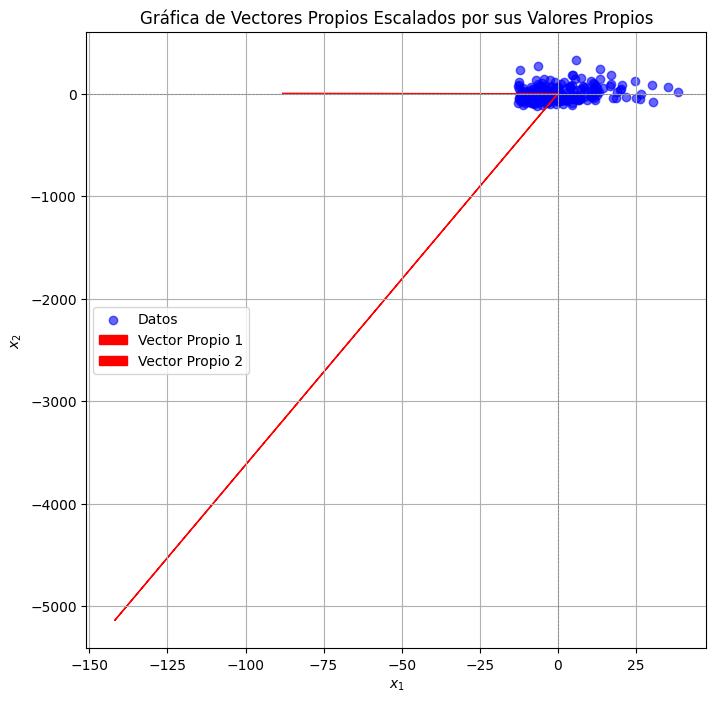

In [ ]:
# Extraer las dos primeras variables numéricas del DataFrame
X = df.select_dtypes(include=['float64', 'int64']).iloc[:, :2].values

# Calcular la media y centrar los datos
X_centered = X - np.mean(X, axis=0)

# Calcular la matriz de covarianza
C = np.cov(X_centered, rowvar=False)

# Calcular valores y vectores propios
valores_propios, vectores_propios = np.linalg.eig(C)

# Escalar vectores propios por sus respectivos valores propios
vector_1 = vectores_propios[:, 0] * valores_propios[0]
vector_2 = vectores_propios[:, 1] * valores_propios[1]

# Gráfica de dispersión de los datos
plt.figure(figsize=(8, 8))
plt.scatter(X_centered[:, 0], X_centered[:, 1], alpha=0.6, color="b", label="Datos")

# Graficar los vectores propios escalados
plt.arrow(0, 0, vector_1[0], vector_1[1], color="r", width=0.05, label="Vector Propio 1")
plt.arrow(0, 0, vector_2[0], vector_2[1], color="r", width=0.05, label="Vector Propio 2")

# Configuración de la gráfica
plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Gráfica de Vectores Propios Escalados por sus Valores Propios")
plt.legend()
plt.grid(True)
plt.show()

## Calcular la proporción de la información capturada por cada componente principal

In [ ]:
# Calcular la proporción de información capturada por cada componente principal
proporcion_pc1 = l[0] / (l[0] + l[1])
proporcion_pc2 = l[1] / (l[0] + l[1])

# Imprimir los resultados
print(f"La primera componente principal captura el {proporcion_pc1 * 100:.1f}% de la información del conjunto original.")
print(f"La segunda componente principal captura el {proporcion_pc2 * 100:.1f}% de la información del conjunto original.")


La primera componente principal captura el 100.0% de la información del conjunto original.
La segunda componente principal captura el 0.0% de la información del conjunto original.


In [ ]:
proporcion_pc1 = l[0] / (l[0] + l[1])
proporcion_pc2 = l[1] / (l[0] + l[1])


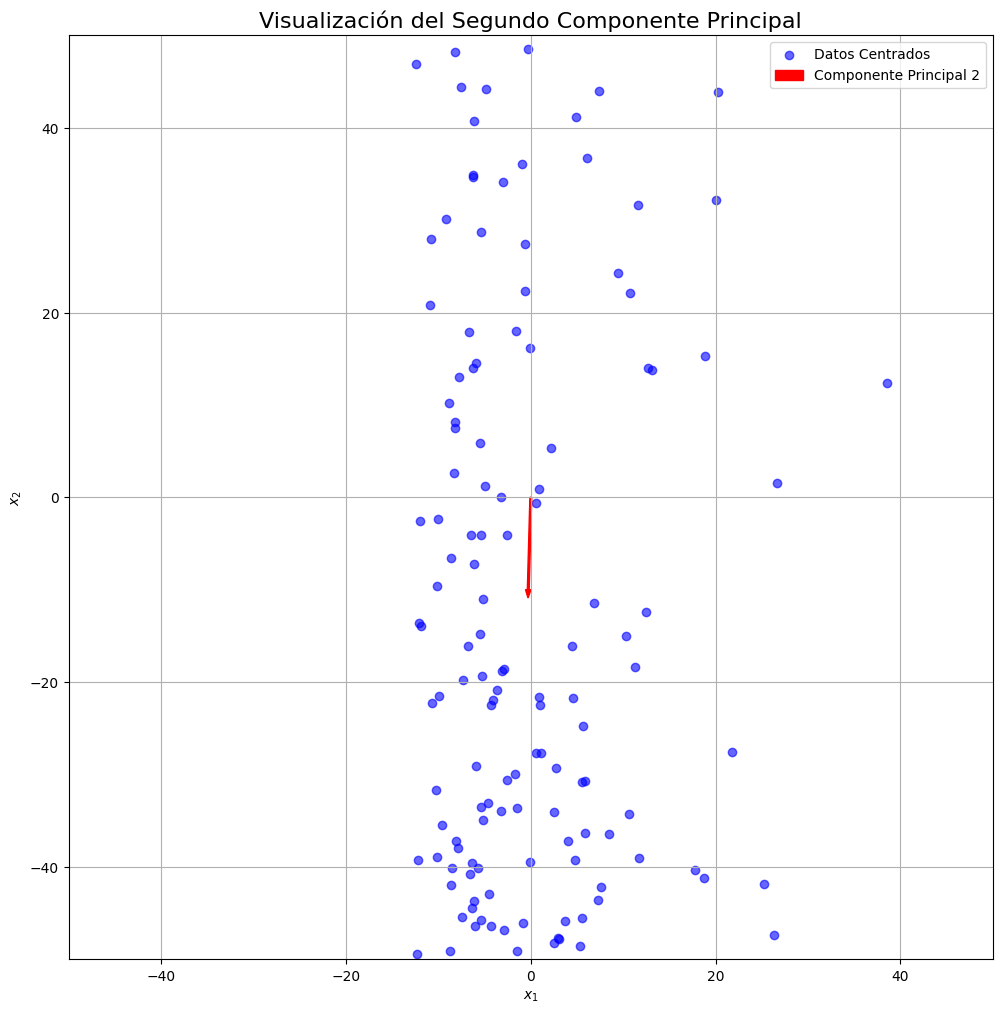

In [ ]:
# Extraer las dos primeras variables numéricas del DataFrame
X = df.select_dtypes(include=['float64', 'int64']).iloc[:, :2].values

# Calcular la media y centrar los datos
X_centered = X - np.mean(X, axis=0)

# Calcular la matriz de covarianza
C = np.cov(X_centered, rowvar=False)

# Calcular valores y vectores propios
valores_propios, vectores_propios = np.linalg.eig(C)

# Variables originales (vectores base)
x1 = np.array([1, 0])
x2 = np.array([0, 1])

# Variables transformadas (componentes principales)
x2t = vectores_propios[:, 1]  # Segundo vector propio (componente principal 2)

# Configuración de la visualización
fig, ax = plt.subplots(figsize=(12, 12))  # Ampliar el tamaño de la figura

# Graficar los datos centrados
plt.scatter(X_centered[:, 0], X_centered[:, 1], color='b', alpha=0.6, label="Datos Centrados")

# Graficar el segundo componente principal escalado
plt.arrow(0, 0, 10 * x2t[0], 10 * x2t[1], width=0.2, color="r", label="Componente Principal 2")

# Ajustar rango de los ejes para una mejor visualización
plt.xlim(-50, 50)
plt.ylim(-50, 50)

# Etiquetas y título
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Visualización del Segundo Componente Principal", fontsize=16)
ax.set_aspect('equal')

# Mostrar leyenda y gráfico
plt.legend()
plt.grid(True)
plt.show()


Debemos proyectar los datos sobre esta componente para que se representen con una sola dimensión. Eso lo logramos multiplicando:

$$\color{red}{X' = Xv_2^T}$$

Observa que los puntos transformados tienen una dimensión de 1 (se encuentran sobre una recta)

In [ ]:
Xp = np.dot(X, np.transpose(v2))
Xp.shape



ValueError: shapes (247,2) and (32,1) not aligned: 2 (dim 1) != 32 (dim 0)

In [ ]:
Xp[:10]

array([[7.97009986e+05, 8.12223351e+01],
       [5.41359845e+04, 6.16928359e+01],
       [9.95899894e+04, 6.25364409e+01],
       [4.66813989e+05, 5.70732123e+01],
       [9.36825989e+05, 7.30304369e+01],
       [1.01078994e+05, 5.48343151e+01],
       [1.55968299e+06, 3.77722078e+01],
       [9.06679923e+04, 7.09216046e+01],
       [7.08159814e+04, 2.69931930e+02],
       [5.91139836e+04, 1.59116371e+02]])

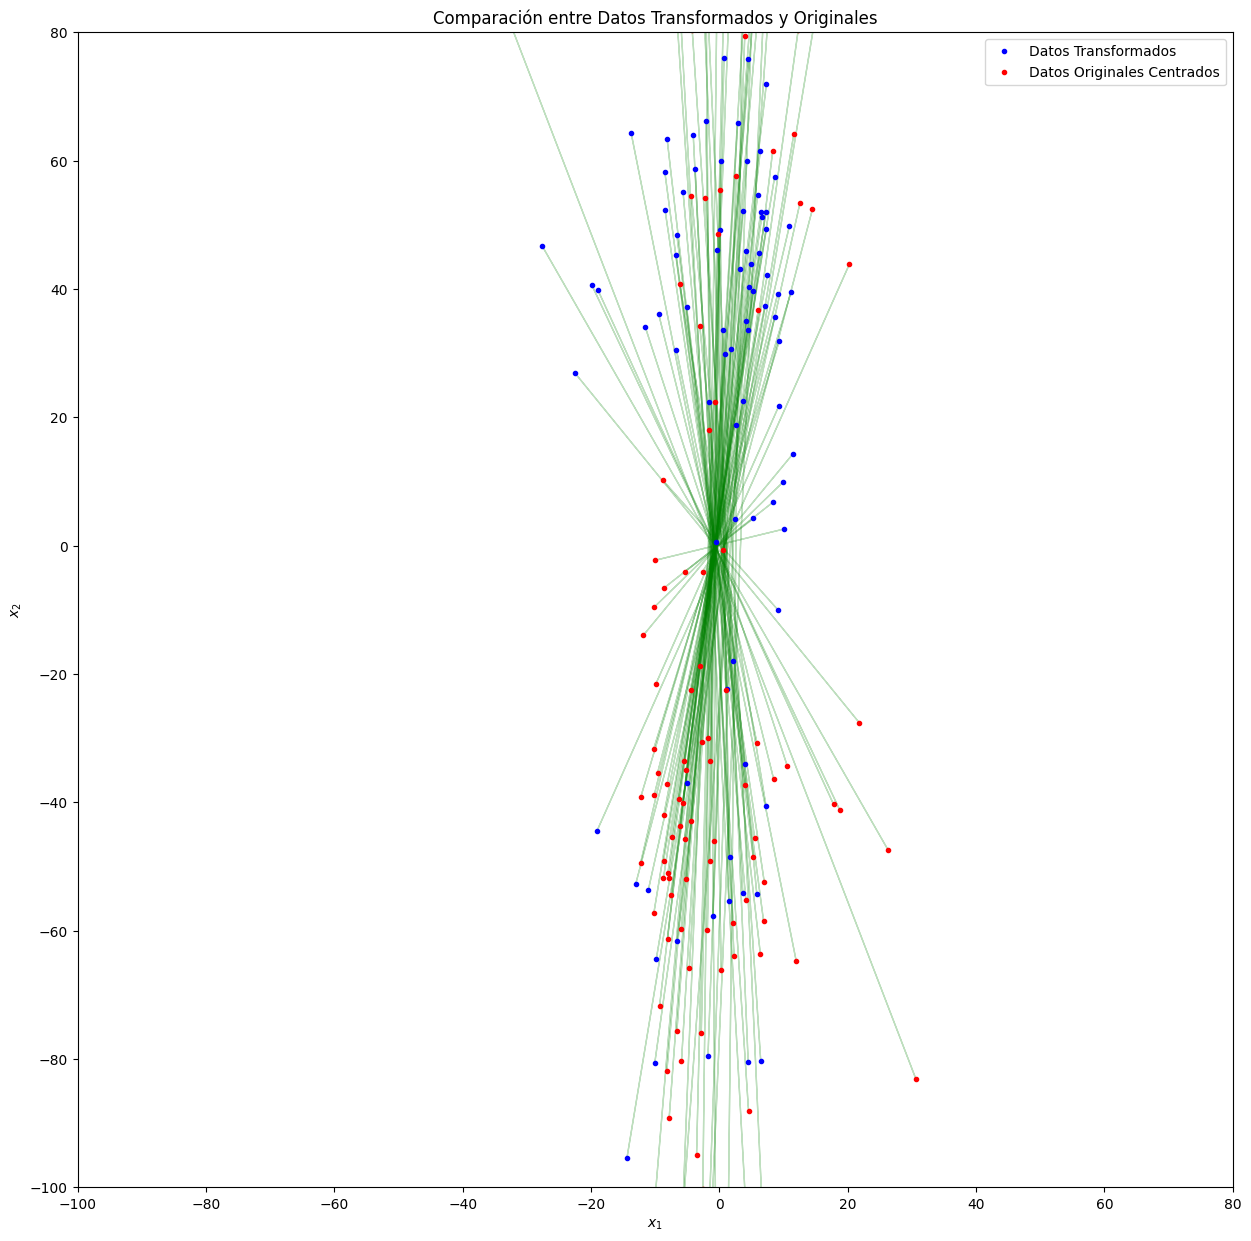

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Extraer las dos primeras variables numéricas del DataFrame
X = df.select_dtypes(include=['float64', 'int64']).iloc[:, :2].values

# Calcular la media y centrar los datos
X_centered = X - np.mean(X, axis=0)

# Calcular la matriz de covarianza
C = np.cov(X_centered, rowvar=False)

# Calcular valores y vectores propios
valores_propios, vectores_propios = np.linalg.eig(C)

# Transformación a componentes principales
Xt = np.dot(X_centered, vectores_propios)  # Datos transformados (componentes principales)
Xp = X_centered  # Datos originales centrados (para comparación)

# Visualización
fig, ax = plt.subplots(figsize=(15, 15))
l = 100  # Número de puntos a graficar

# Ajustar rango de los ejes para una mejor visualización
plt.xlim(-100, 80)
plt.ylim(-100, 80)

# Graficar los datos transformados y originales
plt.plot(Xt[:l, 0], Xt[:l, 1], 'b.', label="Datos Transformados")
plt.plot(Xp[:l, 0], Xp[:l, 1], 'r.', label="Datos Originales Centrados")

# Graficar flechas para conectar puntos transformados y originales
for i in range(l):
    plt.arrow(Xt[i, 0], Xt[i, 1], Xp[i, 0] - Xt[i, 0], Xp[i, 1] - Xt[i, 1], color="g", alpha=0.25)

# Etiquetas y título
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
ax.set_aspect('equal')
plt.title("Comparación entre Datos Transformados y Originales")
plt.legend()
plt.show()


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

Error cuadrático medio (MSE): 84.63955849865476
R-cuadrado (R2): 0.025081027861379113
Coeficientes del modelo: [ 6.11216342e-01  5.15591711e-01 -1.91496815e-01 -8.10431516e-01
 -9.54472747e+03  9.54316829e+03  5.34239395e-01 -2.60953090e+00
  7.41795173e-01 -1.66878162e+00  1.61211336e+00 -7.77840641e-01
  3.04751495e+00 -6.90988097e+00 -3.59093067e+00 -1.43562706e+01
 -1.16540475e+00  1.94685400e+00 -4.60790578e+00 -1.91360254e+00
 -1.87545151e+00 -1.19551456e+00 -1.49336347e+00  5.54922854e+00
  7.44972904e+00 -4.02690755e+00  4.56859641e-01 -1.77256440e+09
 -4.61361027e+08 -1.40424456e+09  3.95193291e+00]


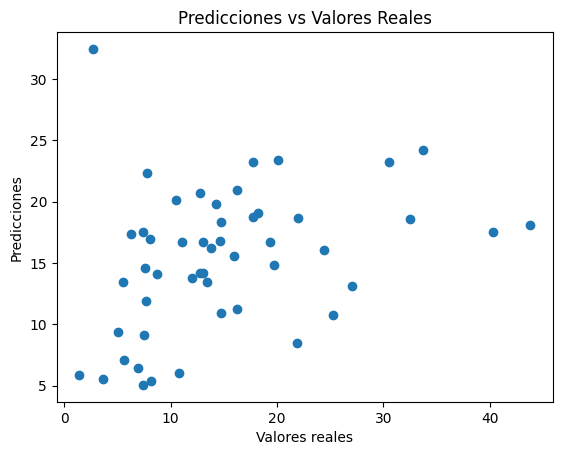

In [ ]:
from sklearn.preprocessing import StandardScaler

# ... (Your existing code) ...

# Dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalar las variables predictoras para normalizar los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Crear y entrenar el modelo de regresión lineal
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Realizar predicciones en el conjunto de prueba
y_pred = model.predict(X_test_scaled)

# Evaluar el modelo
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Imprimir resultados
print(f"Error cuadrático medio (MSE): {mse}")
print(f"R-cuadrado (R2): {r2}")

# Imprimir los coeficientes del modelo (opcional)
print("Coeficientes del modelo:", model.coef_)

# Visualizar las predicciones vs valores reales (opcional)
plt.scatter(y_test, y_pred)
plt.xlabel("Valores reales")
plt.ylabel("Predicciones")
plt.title("Predicciones vs Valores Reales")
plt.show()


In [ ]:
# Crear el modelo de regresión lineal
modelo = LinearRegression()

# Entrenar el modelo con el conjunto de entrenamiento
modelo.fit(X_train_scaled, y_train)

# Obtener los coeficientes y el intercepto del modelo
coeficientes = modelo.coef_
intercepto = modelo.intercept_

# Mostrar el modelo obtenido
print("Modelo de Regresión Lineal Múltiple:")
print(f"T_SEX = {intercepto:.2f} + " + " + ".join([f"{coef:.2f} * {col}" for coef, col in zip(coeficientes, X.columns)]))

Modelo de Regresión Lineal Múltiple:
T_SEX = 13.34 + 0.61 * TS_EXP_ALCOHOL + 0.52 * POB_TOT + -0.19 * SALDO_NETO_MIG + -0.81 * TS_ID + -9544.73 * IM + 9543.17 * IM_100 + 0.53 * ASIST_ESC_MUJ + -2.61 * ASIST_ESC_HOM + 0.74 * PORC_POB_INDIG + -1.67 * IND_FEM + 1.61 * T_PART_ECONOM + -0.78 * IDG + 3.05 * INMUJ_REZ_EDUC + -6.91 * GRADO_PROM + -3.59 * ANALF_TOT + -14.36 * REZ_EDUC + -1.17 * DESOC_ABRT + 1.95 * TS_VIUD_H + -4.61 * TS_VIUD_M + -1.91 * DEP_DEM + -1.88 * DER_HAB_SIN + -1.20 * C_GINI + -1.49 * RAZ_ING + 5.55 * REZ_SOC + 7.45 * POB + -4.03 * POB_EXT + 0.46 * POB_JOV + -1772564404.20 * HAC_SIN + -461361027.39 * HAC_IRR + -1404244558.48 * HAC + 3.95 * HOG_JEF_FEM


In [ ]:
# Predecir los valores para el conjunto de prueba
y_pred = modelo.predict(X_test_scaled)

# Calcular métricas de evaluación
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Mostrar las métricas de evaluación
print(f"Error Cuadrático Medio (MSE): {mse:.2f}")
print(f"Coeficiente de Determinación (R^2): {r2:.2f}")


Error Cuadrático Medio (MSE): 84.64
Coeficiente de Determinación (R^2): 0.03


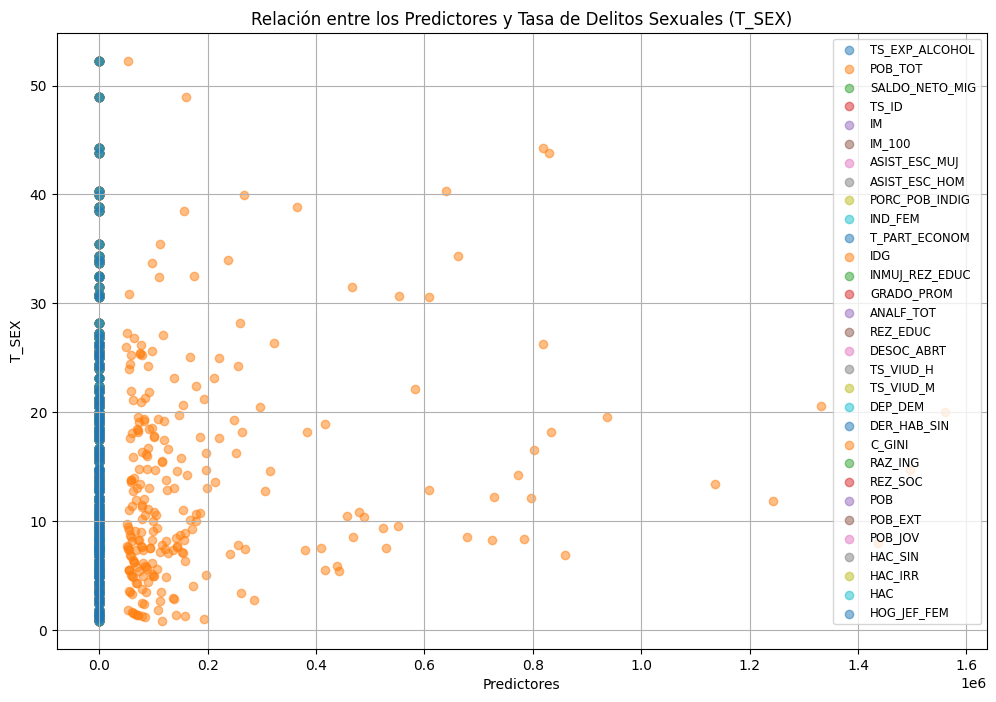

In [ ]:
# Visualización de la relación entre predictores y la variable objetivo
plt.figure(figsize=(12, 8))
for column in X.columns:
    plt.scatter(df[column], df['T_SEX'], alpha=0.5, label=column)

plt.title("Relación entre los Predictores y Tasa de Delitos Sexuales (T_SEX)")
plt.xlabel("Predictores")
plt.ylabel("T_SEX")
plt.legend(loc='upper right', fontsize='small')
plt.grid(True)
plt.show()

#segundo modelo

In [ ]:

# Preparar los datos
X = df.select_dtypes(include=['float64', 'int64'])  # Seleccionar solo columnas numéricas
y = df['T_SEX']  # Variable objetivo

# Escalar los datos antes de aplicar PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Aplicar PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Mostrar la cantidad de varianza explicada por cada componente
varianza_explicada = pca.explained_variance_ratio_ * 100
print(f"Varianza explicada por cada componente principal: {varianza_explicada}")

# Decidir cuántas componentes principales usar (95% de la varianza explicada)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)
num_componentes = np.argmax(varianza_acumulada >= 0.95) + 1
print(f"Usaremos las primeras {num_componentes} componentes principales para el modelo.")

# Usar solo las primeras componentes principales como predictores
X_pca_reducido = X_pca[:, :num_componentes]


Varianza explicada por cada componente principal: [4.65482181e+01 1.02345949e+01 8.72358280e+00 6.48976671e+00
 4.91828817e+00 3.46291212e+00 2.94936197e+00 2.86989930e+00
 2.11444008e+00 1.72120440e+00 1.51121125e+00 1.36674628e+00
 1.25582192e+00 1.14555034e+00 8.30751114e-01 7.47002938e-01
 6.04393402e-01 4.89672041e-01 3.91942549e-01 3.56640104e-01
 2.96738330e-01 2.69860396e-01 2.33434660e-01 1.36794273e-01
 1.02048435e-01 8.27863046e-02 7.42065328e-02 3.73017163e-02
 2.59119836e-02 8.91690818e-03 2.68533648e-09 2.69384257e-19]
Usaremos las primeras 14 componentes principales para el modelo.


In [ ]:
# Dividir los datos en entrenamiento y prueba
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(X_pca_reducido, y, test_size=0.2, random_state=42)

# Crear el modelo de regresión lineal
modelo_pca = LinearRegression()

# Entrenar el modelo con el conjunto de entrenamiento
modelo_pca.fit(X_train_pca, y_train_pca)

# Obtener los coeficientes e intercepto del modelo
coeficientes_pca = modelo_pca.coef_
intercepto_pca = modelo_pca.intercept_

# Mostrar el modelo obtenido
print("Modelo de Regresión Lineal con Componentes Principales:")
for i, coef in enumerate(coeficientes_pca):
    print(f"Componente Principal {i+1}: {coef:.4f}")
print(f"Intercepto: {intercepto_pca:.4f}")


Modelo de Regresión Lineal con Componentes Principales:
Componente Principal 1: -0.5609
Componente Principal 2: -0.5904
Componente Principal 3: 2.2637
Componente Principal 4: 0.8247
Componente Principal 5: 3.1682
Componente Principal 6: 1.6249
Componente Principal 7: -3.6595
Componente Principal 8: -3.4740
Componente Principal 9: 5.2952
Componente Principal 10: 2.9517
Componente Principal 11: 1.5816
Componente Principal 12: -1.3228
Componente Principal 13: 0.1898
Componente Principal 14: -1.3688
Intercepto: 13.7174


In [ ]:
# Predecir los valores para el conjunto de prueba
y_pred_pca = modelo_pca.predict(X_test_pca)

# Calcular métricas de evaluación
mse_pca = mean_squared_error(y_test_pca, y_pred_pca)
r2_pca = r2_score(y_test_pca, y_pred_pca)

# Mostrar las métricas de evaluación
print(f"Error Cuadrático Medio (MSE): {mse_pca:.4f}")
print(f"Coeficiente de Determinación (R²): {r2_pca:.4f}")


Error Cuadrático Medio (MSE): 0.3742
Coeficiente de Determinación (R²): 0.9957


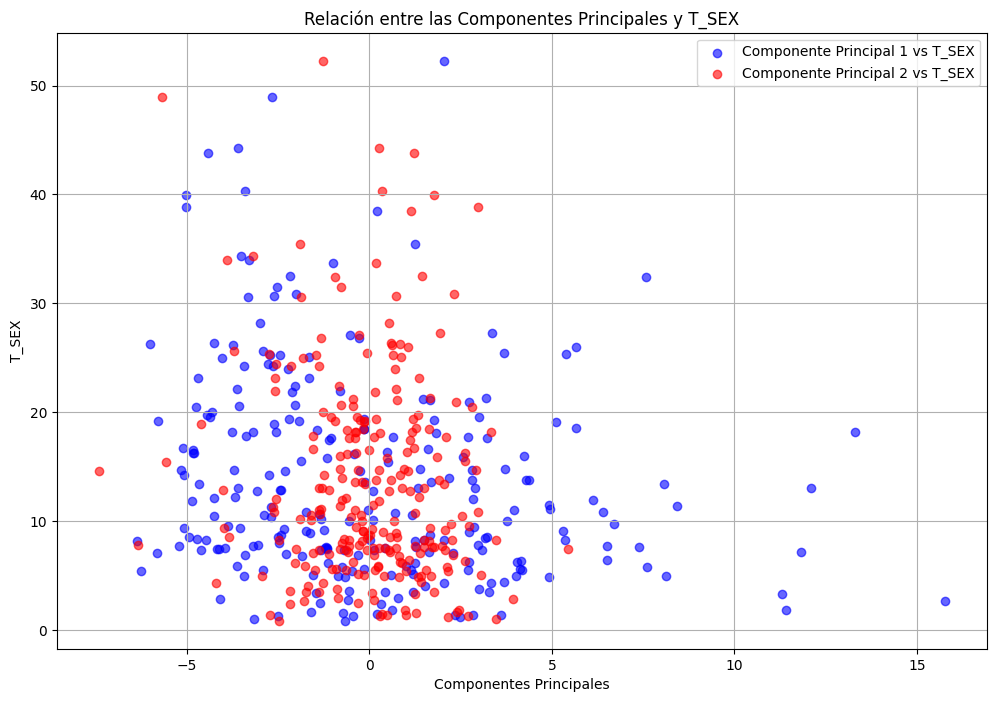

In [ ]:
plt.figure(figsize=(12, 8))

# Graficar las dos primeras componentes principales frente a la variable objetivo
plt.scatter(X_pca_reducido[:, 0], y, alpha=0.6, color="b", label="Componente Principal 1 vs T_SEX")
plt.scatter(X_pca_reducido[:, 1], y, alpha=0.6, color="r", label="Componente Principal 2 vs T_SEX")

# Etiquetas y título
plt.title("Relación entre las Componentes Principales y T_SEX")
plt.xlabel("Componentes Principales")
plt.ylabel("T_SEX")
plt.legend(loc="upper right", fontsize="medium")
plt.grid(True)
plt.show()

In [ ]:
# Calcular las métricas para el modelo basado en los predictores originales
y_pred_original = modelo.predict(X_test_scaled)
mse_original = mean_squared_error(y_test, y_pred_original)
r2_original = r2_score(y_test, y_pred_original)

# Calcular las métricas para el modelo basado en las componentes principales
y_pred_pca = modelo_pca.predict(X_test_pca)
mse_pca = mean_squared_error(y_test_pca, y_pred_pca)
r2_pca = r2_score(y_test_pca, y_pred_pca)

# Mostrar comparación entre los dos modelos
print("Comparación entre los Modelos:")
print("===========================================")
print("Modelo con Predictores Originales:")
print(f" - MSE: {mse_original:.4f}")
print(f" - R²: {r2_original:.4f}")
print("Modelo con Componentes Principales:")
print(f" - MSE: {mse_pca:.4f}")
print(f" - R²: {r2_pca:.4f}")

# Determinar el modelo más adecuado
if r2_original > r2_pca:
    print("\nEl modelo con predictores originales tiene un mejor desempeño.")
else:
    print("\nEl modelo con componentes principales tiene un mejor desempeño.")


Comparación entre los Modelos:
Modelo con Predictores Originales:
 - MSE: 84.6396
 - R²: 0.0251
Modelo con Componentes Principales:
 - MSE: 0.3742
 - R²: 0.9957

El modelo con componentes principales tiene un mejor desempeño.


#Visualización de comparativas

## Calcular MAE para ambos modelos

In [ ]:

mae_original = mean_absolute_error(y_test, y_pred_original)
mae_pca = mean_absolute_error(y_test_pca, y_pred_pca)

print(f"MAE para el modelo original: {mae_original:.4f}")
print(f"MAE para el modelo PCA: {mae_pca:.4f}")


MAE para el modelo original: 6.6665
MAE para el modelo PCA: 0.5021


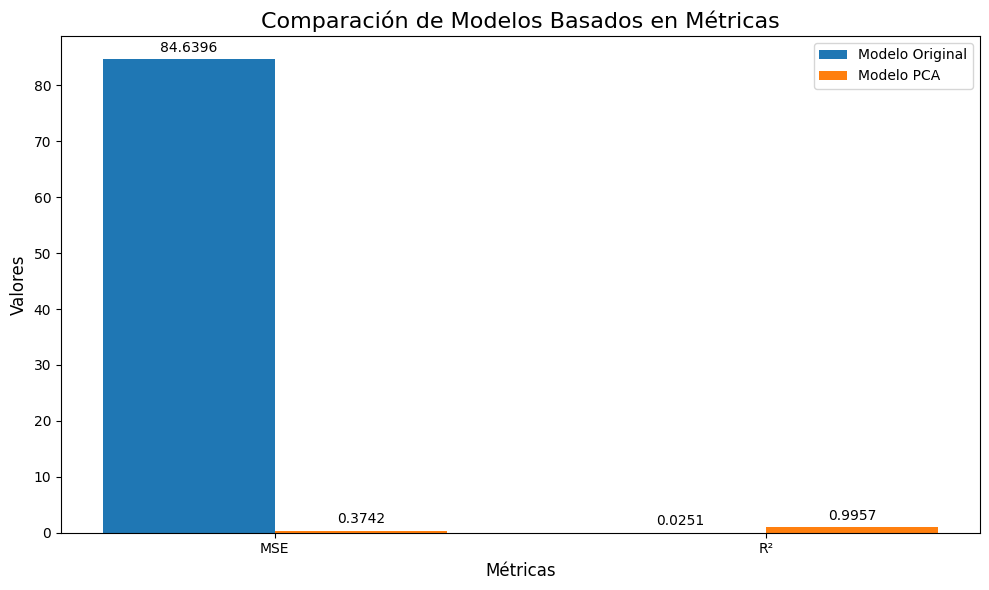

In [ ]:
# Datos de las métricas
metricas = ['MSE', 'R²']
modelo_original = [mse_original, r2_original]
modelo_pca = [mse_pca, r2_pca]

# Crear un gráfico de barras para comparar las métricas
x = np.arange(len(metricas))  # Posiciones para las barras
width = 0.35  # Ancho de las barras

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, modelo_original, width, label='Modelo Original')
bars2 = ax.bar(x + width/2, modelo_pca, width, label='Modelo PCA')

# Etiquetas y título
ax.set_xlabel('Métricas', fontsize=12)
ax.set_ylabel('Valores', fontsize=12)
ax.set_title('Comparación de Modelos Basados en Métricas', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.legend()

# Agregar valores sobre las barras
for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # Desplazamiento vertical
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()



# <font style color="RED"> #Diferente tipos de visualización de los datos</font>

#Grafica de residuos

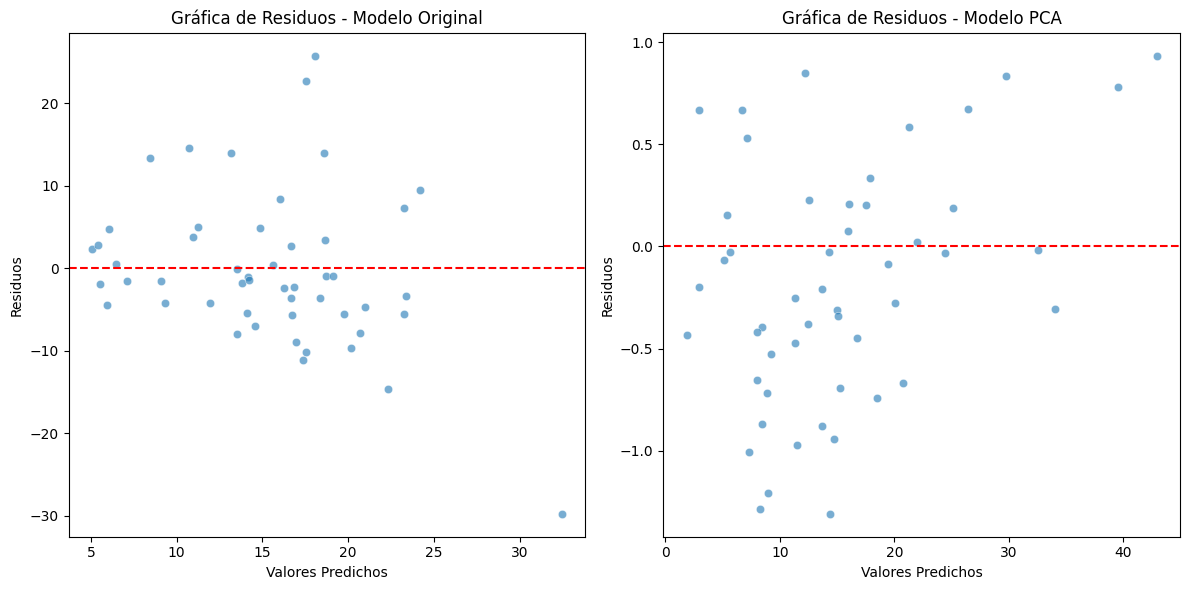

In [ ]:
# Calcular los residuos
residuos_original = y_test - y_pred_original
residuos_pca = y_test_pca - y_pred_pca

# Crear la figura
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Gráfico de residuos para el modelo original
sns.scatterplot(x=y_pred_original, y=residuos_original, alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='r', linestyle='--')
axes[0].set_title("Gráfica de Residuos - Modelo Original")
axes[0].set_xlabel("Valores Predichos")
axes[0].set_ylabel("Residuos")

# Gráfico de residuos para el modelo PCA
sns.scatterplot(x=y_pred_pca, y=residuos_pca, alpha=0.6, ax=axes[1])
axes[1].axhline(y=0, color='r', linestyle='--')
axes[1].set_title("Gráfica de Residuos - Modelo PCA")
axes[1].set_xlabel("Valores Predichos")
axes[1].set_ylabel("Residuos")

plt.tight_layout()
plt.show()


#Gráfico de Paridad (Actual vs. Predicho)

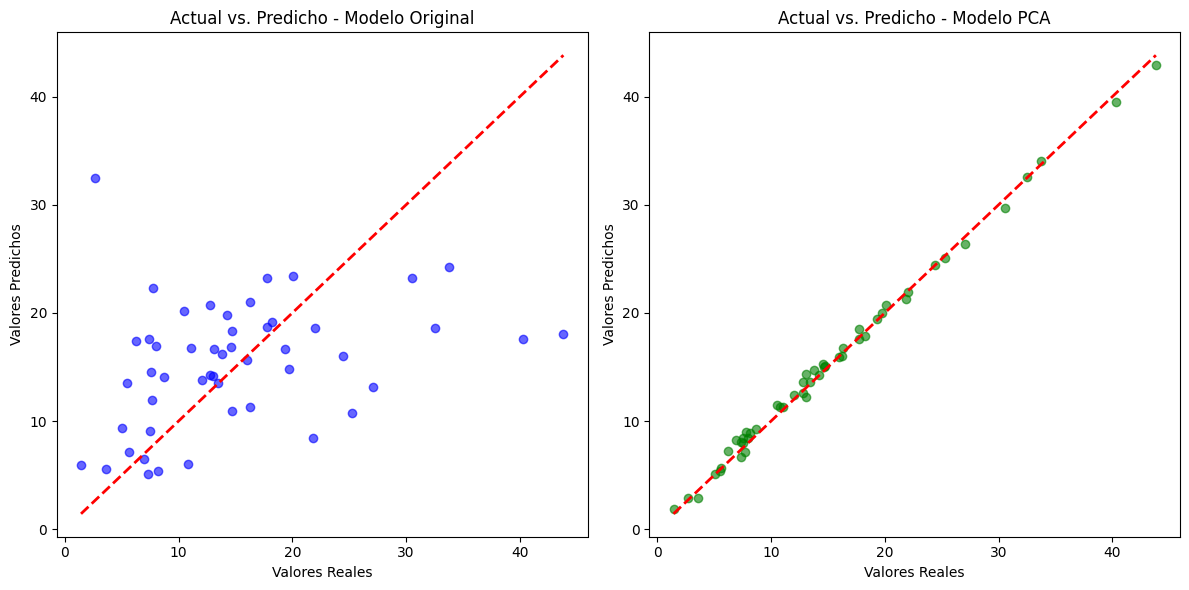

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Gráfico para el modelo original
ax[0].scatter(y_test, y_pred_original, alpha=0.6, color="blue")
ax[0].plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], '--r', linewidth=2)
ax[0].set_title("Actual vs. Predicho - Modelo Original")
ax[0].set_xlabel("Valores Reales")
ax[0].set_ylabel("Valores Predichos")

# Gráfico para el modelo PCA
ax[1].scatter(y_test_pca, y_pred_pca, alpha=0.6, color="green")
ax[1].plot([min(y_test_pca), max(y_test_pca)], [min(y_test_pca), max(y_test_pca)], '--r', linewidth=2)
ax[1].set_title("Actual vs. Predicho - Modelo PCA")
ax[1].set_xlabel("Valores Reales")
ax[1].set_ylabel("Valores Predichos")

plt.tight_layout()
plt.show()


# Calcular RMSE para ambos modelos

In [ ]:
rmse_original = np.sqrt(mse_original)
rmse_pca = np.sqrt(mse_pca)

print(f"RMSE para el modelo original: {rmse_original:.4f}")
print(f"RMSE para el modelo PCA: {rmse_pca:.4f}")

RMSE para el modelo original: 9.2000
RMSE para el modelo PCA: 0.6117


#historigama de residuos

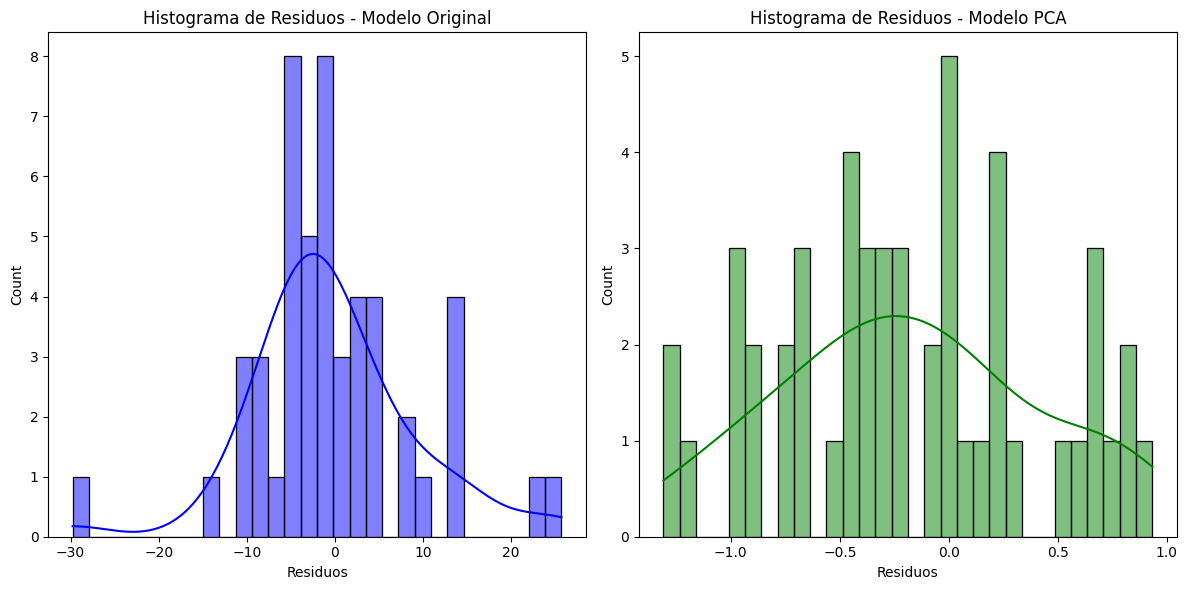

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Histograma de residuos para el modelo original
sns.histplot(residuos_original, bins=30, kde=True, color="blue", ax=ax[0])
ax[0].set_title("Histograma de Residuos - Modelo Original")
ax[0].set_xlabel("Residuos")

# Histograma de residuos para el modelo PCA
sns.histplot(residuos_pca, bins=30, kde=True, color="green", ax=ax[1])
ax[1].set_title("Histograma de Residuos - Modelo PCA")
ax[1].set_xlabel("Residuos")

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import explained_variance_score

# Calcular explained variance para ambos modelos
evs_original = explained_variance_score(y_test, y_pred_original)
evs_pca = explained_variance_score(y_test_pca, y_pred_pca)

print(f"Explained Variance para el modelo original: {evs_original:.4f}")
print(f"Explained Variance para el modelo PCA: {evs_pca:.4f}")


Explained Variance para el modelo original: 0.0260
Explained Variance para el modelo PCA: 0.9961


#Visualización de Dispersión: Valores Reales vs Predicciones
python
Copiar
Editar


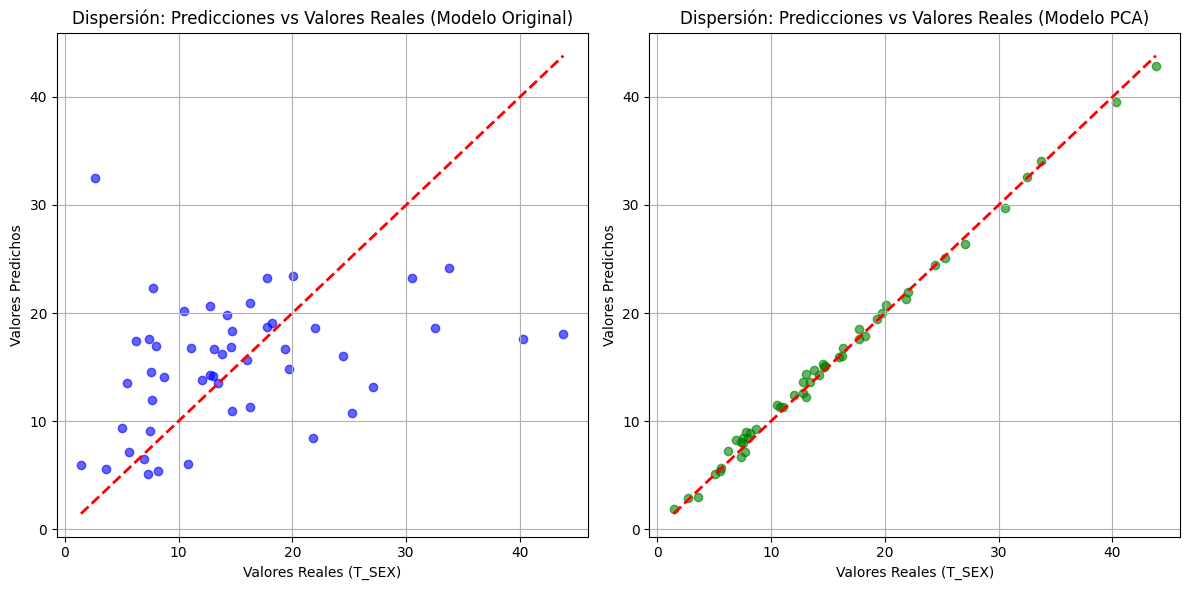

In [ ]:
import matplotlib.pyplot as plt

# Crear la figura con dos subgráficos
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Gráfico de dispersión para el modelo con predictores originales
ax[0].scatter(y_test, y_pred_original, alpha=0.6, color="blue")
ax[0].plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], '--r', linewidth=2)
ax[0].set_title("Dispersión: Predicciones vs Valores Reales (Modelo Original)")
ax[0].set_xlabel("Valores Reales (T_SEX)")
ax[0].set_ylabel("Valores Predichos")
ax[0].grid(True)

# Gráfico de dispersión para el modelo basado en componentes principales
ax[1].scatter(y_test_pca, y_pred_pca, alpha=0.6, color="green")
ax[1].plot([min(y_test_pca), max(y_test_pca)], [min(y_test_pca), max(y_test_pca)], '--r', linewidth=2)
ax[1].set_title("Dispersión: Predicciones vs Valores Reales (Modelo PCA)")
ax[1].set_xlabel("Valores Reales (T_SEX)")
ax[1].set_ylabel("Valores Predichos")
ax[1].grid(True)

plt.tight_layout()
plt.show()


# <font color="yellow"> TOP TEN MUNICIPIOS CON ALTA INCIDENCIA EN DELITOS SEXUALES EN EL PAIS
</font>

In [ ]:

# Cargar el archivo Nombres.xls para obtener los nombres descriptivos
nombres_path = "Nombres.xls"  # Ruta del archivo en el entorno
nombres_df = pd.read_excel(nombres_path)

# Crear un diccionario de mapeo de nombres
column_mapping = dict(zip(nombres_df['COLUMNA'], nombres_df['DESCRIPCIÓN']))

# Cargar el archivo indicadores.csv
file_path = "indicadores.csv"  # Ruta del archivo en el entorno
df = pd.read_csv(file_path)

# Verificar si las columnas necesarias existen
if 'T_SEX' in df.columns and 'MUN' in df.columns:
    # Seleccionar los 10 municipios con mayor incidencia en delitos sexuales
    top_10_municipios = df.nlargest(10, 'T_SEX')[['MUN', 'T_SEX']]

    # Asegurarse de que las claves en column_mapping coincidan con los nombres de columna actuales
    #print(top_10_municipios.columns) # Print the current column names
    #print(column_mapping.keys()) # Print the keys in your mapping dictionary

    # Ajustar column_mapping para que las claves coincidan con 'MUN' y 'T_SEX'
    column_mapping = {
        'MUN': column_mapping.get('MUN', 'Nombre del Municipio'),  # Usar valor por defecto si no se encuentra 'MUN'
        'T_SEX': column_mapping.get('T_SEX', 'Tasa de delitos sexuales') # Use default if 'T_SEX' not found
    }

    # Renombrar columnas para mostrar nombres completos
    top_10_municipios = top_10_municipios.rename(columns=column_mapping)

    # Visualizar el DataFrame resultante
    from IPython.display import display
    display(top_10_municipios)

    # (Opcional) Visualizar en un gráfico de barras si lo deseas
    # ...
else:
    print("La columna 'T_SEX' o 'MUN' no está en el archivo. Verifica el contenido del CSV.")

,Nombre del municipio,Tasa de delitos sexuales (secretaría de seguridad pública 2011)
191,Teapa,52.28
153,Solidaridad,48.96
93,Toluca,44.29
237,Mérida,43.82
183,Centro,40.29
74,Pachuca de Soto,39.95
110,Cuernavaca,38.89
134,San Juan Bautista Tuxtepec,38.52
20,Tecomán,35.48
152,Benito Juárez,34.33


# <font color="yellow"> PRINCIPALES VARIABLES DE ESTE TIPO DE INCIDENCIA EN DELITOS SEXUALES
</font>

,T_SEX
Tasa de participación económica,0.308503
Rezago educativo (INEGI),0.299364
Dependencia demográfica,0.295940
Rezago educativo (INMUJERES),0.294112
Grado de estudios promedio,0.272351
Índice de desarrollo relativo al género,0.241909
Porcentaje de viudos,0.240439
índice de marginación (INMUJERES),0.208071
índice de marginación en porcentaje (INMUJERES),0.208070
Analfabetismo,0.205905


<ipython-input-141-0111410c1d23>:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_variables.values, y=top_10_variables.index, palette="Reds_r")


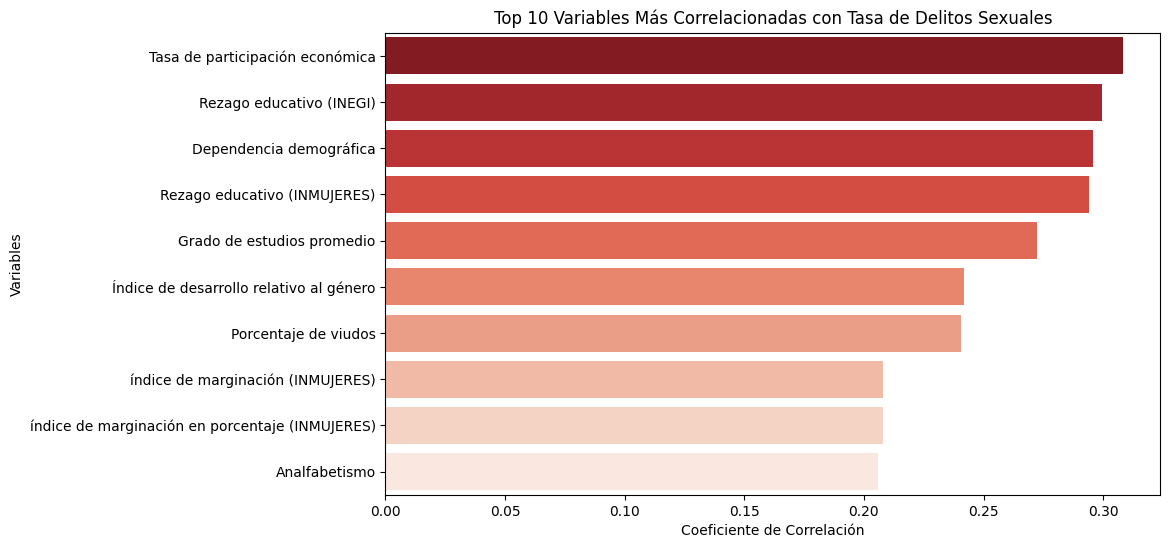

In [ ]:
# Cargar el archivo CSV
file_path = "indicadores.csv"  # Ruta del archivo en el entorno
df = pd.read_csv(file_path)

# Verificar si la columna 'T_SEX' existe
if 'T_SEX' in df.columns:
    # Seleccionar solo columnas numéricas para calcular la correlación
    numerical_df = df.select_dtypes(include=np.number)  # Filtra columnas numéricas

    # Calcular la matriz de correlación
    correlaciones = numerical_df.corr()['T_SEX'].dropna().abs().sort_values(ascending=False)

    # Seleccionar las 10 variables con mayor correlación con 'T_SEX'
    top_10_variables = correlaciones[1:11]  # Excluye 'T_SEX' misma

    # Reemplazar los nombres de las variables por sus nombres completos
    top_10_variables.index = [column_mapping.get(col, col) for col in top_10_variables.index]

    # Visualizar en un DataFrame
    from IPython.display import display
    display(top_10_variables)

    # Visualizar en un gráfico de barras
    plt.figure(figsize=(10, 6))
    sns.barplot(x=top_10_variables.values, y=top_10_variables.index, palette="Reds_r")
    plt.xlabel("Coeficiente de Correlación")
    plt.ylabel("Variables")
    plt.title("Top 10 Variables Más Correlacionadas con Tasa de Delitos Sexuales")
    plt.show()
else:
    print("La columna 'T_SEX' no está en el archivo. Verifica el contenido del CSV.")


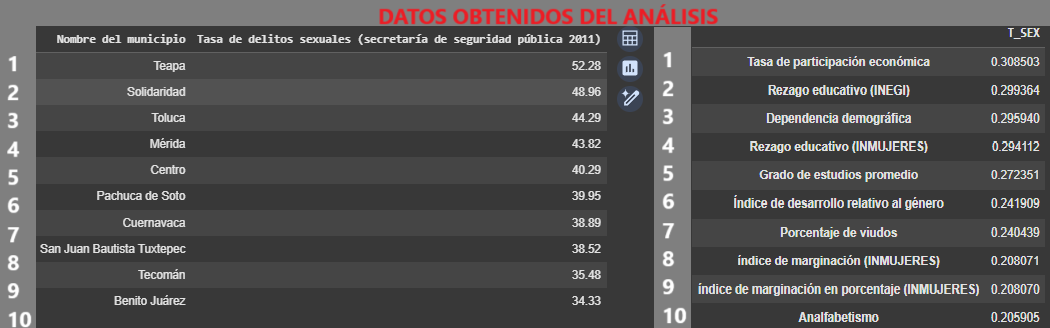

# <font color="yellow"> CONCLUSIÓN
El análisis realizado sobre la incidencia de delitos sexuales en México nos permitió identificar los factores más relevantes que contribuyen a este grave problema social. Las variables asociadas a condiciones socioeconómicas, desigualdad y rezago educativo destacan como los principales detonantes. Este estudio evidencia la necesidad de implementar políticas públicas enfocadas en abordar estas causas estructurales, mejorando las condiciones de vida y promoviendo la equidad, especialmente en los municipios con mayor incidencia. Los resultados obtenidos subrayan la importancia de una visión integral para mitigar este tipo de delitos y proteger a las poblaciones más vulnerables, especialmente a las mujeres.
